# Textual Emotion Recognition
### Enabling machines to understand human emotions with LSTM, CNN and hybrid deep learning models

**CVIS Hands-on Training Project, BRAC University, Summer 2025**
**Faiaz Abrar Zaman Pronoy (22301061)**, supervised by Dr. Md. Ashraful Alam, CVIS Research Lab

When you read *"I'm so happy today!"* you know the feeling behind it at once. This project teaches a
computer to do the same: read a sentence and name the emotion in it, one of **sadness, joy, love,
anger, fear and surprise**.

| | |
|---|---|
| **Task** | Multi-class text classification (6 emotions) |
| **Data** | 20,000 English sentences from Twitter, each labelled with one emotion |
| **Models** | A classic machine learning baseline, Bi-LSTM, 1D CNN, hybrid CNN-LSTM, Bi-LSTM with attention and a fine-tuned RoBERTa Transformer |
| **Extras** | Five ways of combining models, explainability (attention and word importance), calibration and a live predictor |

**How to read this notebook:** scroll from top to bottom. Each step has a short note on what we do and
why, then the code, then the result.

**Running it:** on Kaggle, add the [Emotion Dataset](https://www.kaggle.com/datasets/parulpandey/emotion-dataset),
choose a **GPU** accelerator and turn **Internet on** (RoBERTa is downloaded once). Locally or on Colab,
the notebook reads the files in `data/` and downloads them from this repository if they are missing.

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import logging
logging.getLogger('tensorflow').setLevel(logging.ERROR)
import re
import random
import warnings
warnings.filterwarnings('ignore')
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud, STOPWORDS

import tensorflow as tf
from tensorflow.keras import layers, Model, Sequential
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score, f1_score,
                             cohen_kappa_score, roc_curve, auc, precision_recall_curve,
                             average_precision_score)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.manifold import TSNE
from nltk.stem import PorterStemmer

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
tf.get_logger().setLevel('ERROR')

BLOCKED = {'fuck', 'fucked', 'fucking', 'shit', 'shitty', 'slutty', 'slut', 'horny', 'bitch', 'bitchy',
           'sexy', 'naughty', 'pissed', 'crap', 'dick', 'ass', 'damn', 'damned', 'hell', 'whore'}

EMOTIONS = ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']
COLORS = {'sadness': '#3D5A98', 'joy': '#F2B705', 'love': '#E0457B',
          'anger': '#C0392B', 'fear': '#7D3C98', 'surprise': '#17A589'}
MODEL_COLORS = {'TF-IDF + LogReg': '#7F8C8D', 'Bi-LSTM': '#E4572E', 'CNN': '#17BEBB',
                'Hybrid CNN-LSTM': '#2E5EAA', 'Attention Bi-LSTM': '#8E44AD', 'RoBERTa': '#D35400'}
sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.titlesize': 13,
                     'axes.spines.top': False, 'axes.spines.right': False})
for gpu in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(gpu, True)
print(f'TensorFlow {tf.__version__}, running on {"GPU" if tf.config.list_physical_devices("GPU") else "CPU"}')

TensorFlow 2.20.0, running on GPU


---
## 1. Load Dataset

The [Emotion Dataset](https://www.kaggle.com/datasets/parulpandey/emotion-dataset) comes already split
into training, validation and test files. The original test file has 2,000 sentences; we move half of
them to validation so the models have more data to choose their settings on, and keep **1,000 sentences
as a final test** that nothing is tuned on.

In [2]:
import glob
found = glob.glob('data/training.csv') or glob.glob('/kaggle/input/**/training.csv', recursive=True)
DATA = os.path.dirname(found[0]) if found else 'https://raw.githubusercontent.com/FaiazPronoy/Textual-Emotion-Recognition/main/data'
train_data = pd.read_csv(f'{DATA}/training.csv')
val_data = pd.read_csv(f'{DATA}/validation.csv')
test_data = pd.read_csv(f'{DATA}/test.csv')
print(f'Original    train {len(train_data):,}  validation {len(val_data):,}  test {len(test_data):,}')

val_data = pd.concat([val_data, test_data.iloc[1000:]], ignore_index=True)
test_data = test_data.iloc[:1000].reset_index(drop=True)
print(f'Used        train {len(train_data):,}  validation {len(val_data):,}  test {len(test_data):,}')

for df in (train_data, val_data, test_data):
    df['emotion'] = df['label'].map(dict(enumerate(EMOTIONS)))
polite = ~train_data['text'].str.contains('|'.join(BLOCKED))
train_data[polite].sample(6, random_state=SEED)

Original    train 16,000  validation 2,000  test 2,000
Used        train 16,000  validation 3,000  test 1,000


,text,label,emotion
8714,ive eaten today well ill give you the highligh...,0,sadness
15998,i feel like this was such a rude comment and i...,3,anger
7177,i had suppressed my homosexual feelings so muc...,1,joy
15736,i feel so empty while i m turning your corpse ...,0,sadness
5682,i feel a bit overwhelmed in some areas so i ma...,5,surprise
7171,i trained my heart and mind to receive and bel...,0,sadness


---
## 2. Data Exploration

What do the sentences look like, how balanced are the emotions, and is the data clean? One check matters
more than it looks: if a test sentence also appears in the training data, the model has already seen the
answer, and the test score is inflated. We remove such sentences, and exact duplicates, from training.

Missing values: 0
Duplicate sentences in train: 31
Validation or test sentences that also appear in train: 16
Removed 47 training sentences. Training set: 15,953


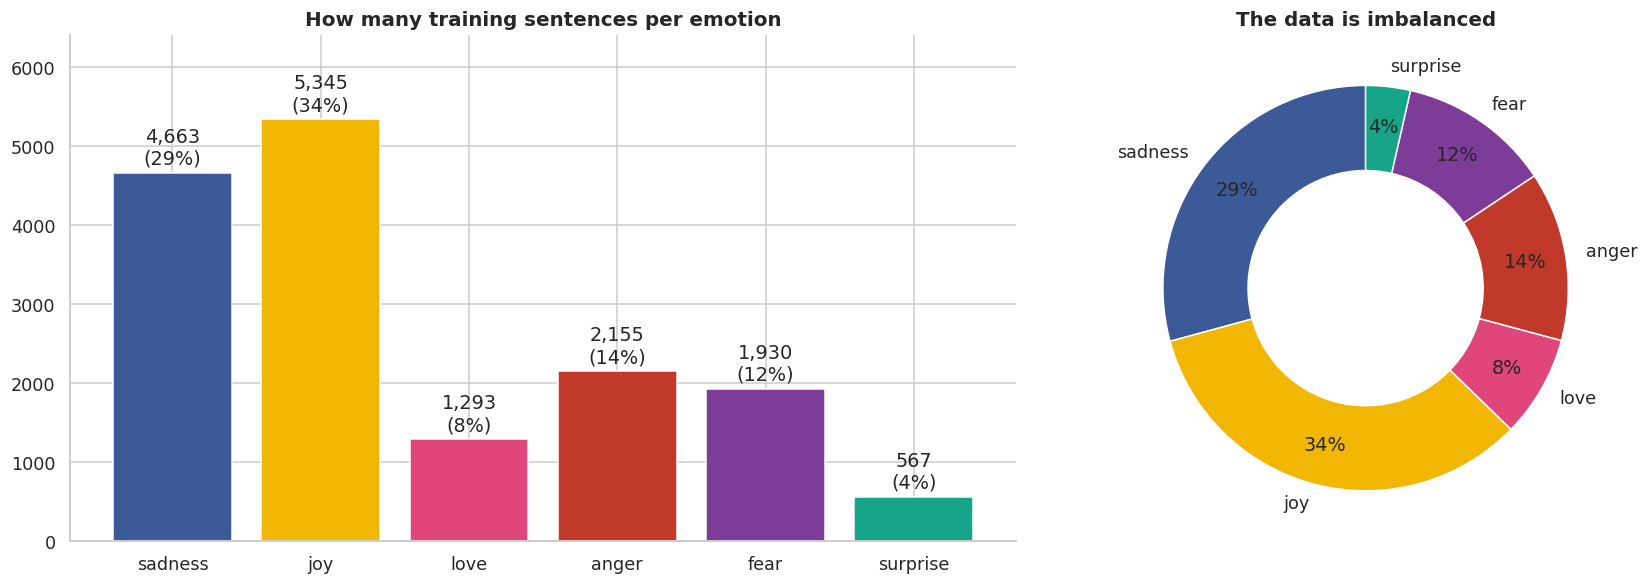

joy has 9.4x more examples than surprise.


In [3]:
print('Missing values:', int(train_data.isna().sum().sum() + val_data.isna().sum().sum() + test_data.isna().sum().sum()))
print('Duplicate sentences in train:', train_data['text'].duplicated().sum())
overlap = set(train_data['text']) & (set(test_data['text']) | set(val_data['text']))
print('Validation or test sentences that also appear in train:', len(overlap))

before = len(train_data)
train_data = train_data.drop_duplicates('text')
train_data = train_data[~train_data['text'].isin(overlap)].reset_index(drop=True)
print(f'Removed {before - len(train_data)} training sentences. Training set: {len(train_data):,}')

counts = train_data['emotion'].value_counts().reindex(EMOTIONS)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={'width_ratios': [1.3, 1]})
bars = axes[0].bar(counts.index, counts.values, color=[COLORS[e] for e in counts.index])
axes[0].bar_label(bars, labels=[f'{v:,}\n({v/len(train_data):.0%})' for v in counts.values], padding=3)
axes[0].set_title('How many training sentences per emotion')
axes[0].set_ylim(0, counts.max() * 1.2)

axes[1].pie(counts.values, labels=counts.index, colors=[COLORS[e] for e in counts.index],
            autopct='%1.0f%%', startangle=90, pctdistance=0.8,
            wedgeprops={'width': 0.42, 'edgecolor': 'white'})
axes[1].set_title('The data is imbalanced')
plt.tight_layout(); plt.show()
print(f'joy has {counts["joy"]/counts["surprise"]:.1f}x more examples than surprise.')

**What we see:** joy and sadness make up more than half of the data, while surprise has under 4%.
A model can score well just by favouring the big classes, so we will (a) use **class weights** in
training, so each surprise mistake counts more, and (b) report **macro F1**, which treats every emotion
equally, alongside plain accuracy.

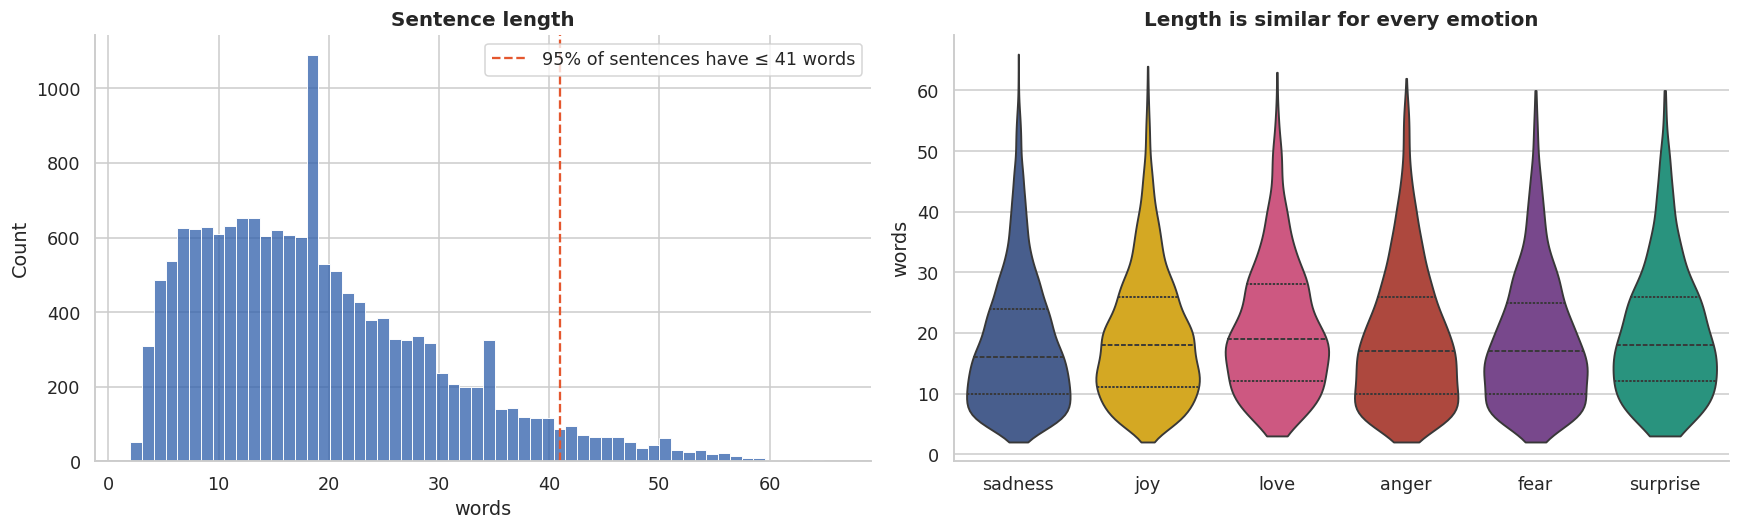

Average 19.2 words, longest 66 words.


In [4]:
for df in (train_data, val_data, test_data):
    df['words'] = df['text'].str.split().str.len()
clean_words = lambda t: re.sub(r'[^a-z\s]', ' ', t.lower()).split()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.histplot(train_data['words'], bins=60, color='#2E5EAA', ax=axes[0])
p95 = int(train_data['words'].quantile(0.95))
axes[0].axvline(p95, color='#E4572E', ls='--', label=f'95% of sentences have ≤ {p95} words')
axes[0].set_title('Sentence length'); axes[0].legend()

sns.violinplot(data=train_data, x='emotion', y='words', order=EMOTIONS,
               palette=COLORS, ax=axes[1], cut=0, inner='quartile')
axes[1].set_title('Length is similar for every emotion'); axes[1].set_xlabel('')
plt.tight_layout(); plt.show()
print(f"Average {train_data['words'].mean():.1f} words, longest {train_data['words'].max()} words.")

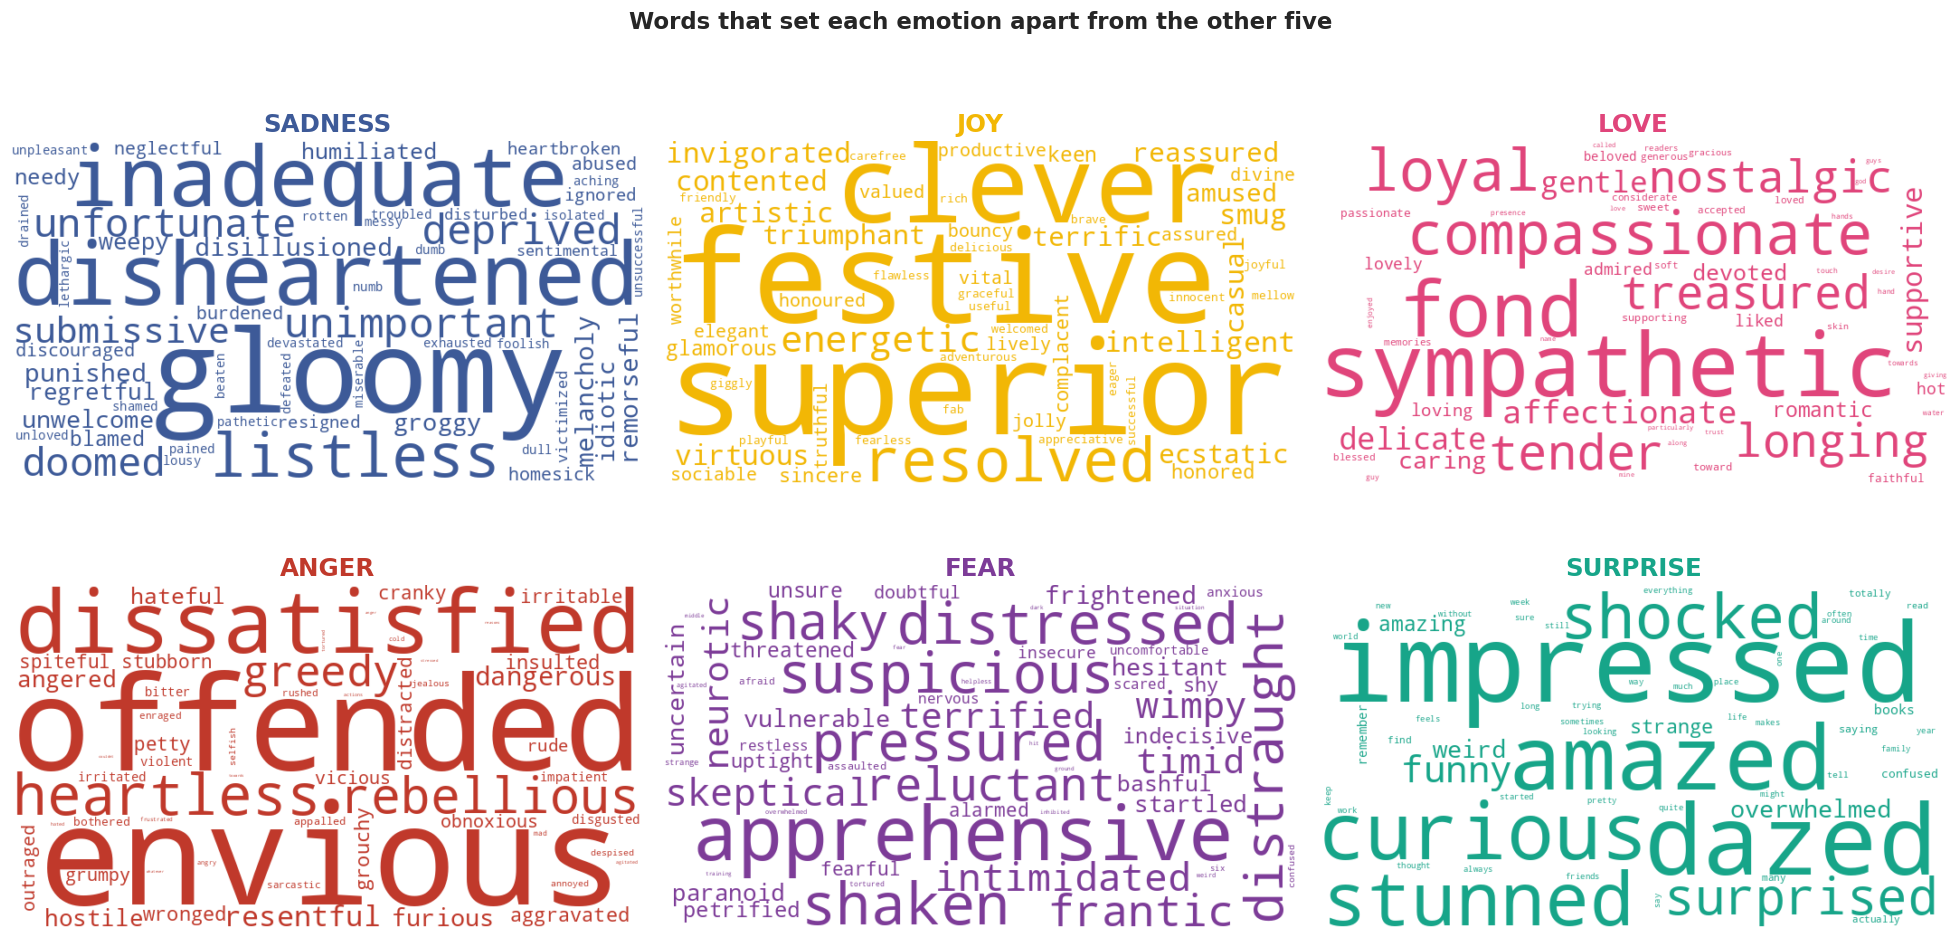

In [5]:
skip = STOPWORDS | BLOCKED | {'feel', 'feeling', 'feelings', 'felt', 'im', 'ive', 'don', 'dont', 'didnt',
                               'really', 'little', 'bit', 'thing', 'things', 'being', 'know', 'think', 'people'}
word_counts = {e: Counter(w for t in train_data.loc[train_data['emotion'] == e, 'text']
                          for w in clean_words(t) if w not in skip and len(w) > 2) for e in EMOTIONS}
total = sum(word_counts.values(), Counter())

fig, axes = plt.subplots(2, 3, figsize=(18, 9.5))
for ax, emotion in zip(axes.flat, EMOTIONS):
    own, n_own = word_counts[emotion], sum(word_counts[emotion].values())
    n_rest = sum(total.values()) - n_own
    score = {w: (c / n_own) / ((total[w] - c + 1) / n_rest) for w, c in own.items() if c >= 8}
    top = dict(sorted(score.items(), key=lambda kv: -kv[1])[:55])
    base = COLORS[emotion]
    wc = WordCloud(width=700, height=380, background_color='white', random_state=SEED,
                   color_func=lambda *a, **k: base).generate_from_frequencies(top)
    ax.imshow(wc, interpolation='bilinear'); ax.axis('off')
    ax.set_title(emotion.upper(), color=base, fontsize=16)
fig.suptitle('Words that set each emotion apart from the other five', fontsize=15, fontweight='bold')
plt.tight_layout(); plt.show()

**What we see:** each cloud shows the words that are far more common in that emotion than in the
others, so filler words disappear and the clouds are clearly different. Almost every sentence starts with
"i feel", so the emotion lives in one or two key words. That is good news for models that learn to
spot word patterns.

---
## 3. Text Preprocessing

Raw text has noise the model does not need. We:

* make everything **lowercase**, so *Happy* and *happy* are the same word,
* remove **digits and symbols**,
* squeeze repeated spaces.

We deliberately **keep stop words** like *not* and *never*: removing them would turn
*"i do not feel happy"* into *"feel happy"*, flipping the emotion.

In [6]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    return ' '.join(text.split())


for df in (train_data, val_data, test_data):
    df['clean'] = df['text'].apply(clean_text)

print(train_data[['text', 'clean']].head(3).to_string())

                                                                                                           text                                                                                                         clean
0                                                                                       i didnt feel humiliated                                                                                       i didnt feel humiliated
1  i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake  i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake
2                                                              im grabbing a minute to post i feel greedy wrong                                                              im grabbing a minute to post i feel greedy wrong


---
## 4. Tokenization and Stemming

* **Stemming** cuts words to their root, so *feeling, feels, felt* become one token. This shrinks the
  vocabulary and lets rare forms share what the model learns about common ones.
* **Tokenization** turns each word into a number (its position in the vocabulary).
* **Padding** makes every sentence the same length, which neural networks need.

We keep the 10,000 most common stems and pad to the length that covers almost every sentence.

In [7]:
stemmer = PorterStemmer()
stem_text = lambda t: ' '.join(stemmer.stem(w) for w in t.split())

for df in (train_data, val_data, test_data):
    df['stemmed'] = df['clean'].apply(stem_text)

MAX_WORDS = 10_000
MAX_LEN = int(train_data['words'].max()) + 4

tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token='<OOV>')
tokenizer.fit_on_texts(train_data['stemmed'])

to_seq = lambda s: pad_sequences(tokenizer.texts_to_sequences(s), maxlen=MAX_LEN, padding='post', truncating='post')
X_train, X_val, X_test = (to_seq(d['stemmed']) for d in (train_data, val_data, test_data))
y_train, y_val, y_test = (d['label'].values for d in (train_data, val_data, test_data))
NUM_CLASSES = len(EMOTIONS)
y_train_cat, y_val_cat, y_test_cat = (to_categorical(y, NUM_CLASSES) for y in (y_train, y_val, y_test))

print(f'Unique stems: {len(tokenizer.word_index):,}   using the top {MAX_WORDS:,}')
print(f'Padded length: {MAX_LEN}   X_train {X_train.shape}')
print('Example:', train_data["stemmed"][1][:70], '->', X_train[1][:12], '...')

Unique stems: 10,483   using the top 10,000
Padded length: 70   X_train (15953, 70)
Example: i can go from feel so hopeless to so damn hope just from be around som -> [  2  41  48  65   3  14 489   5  14 845 156  31] ...


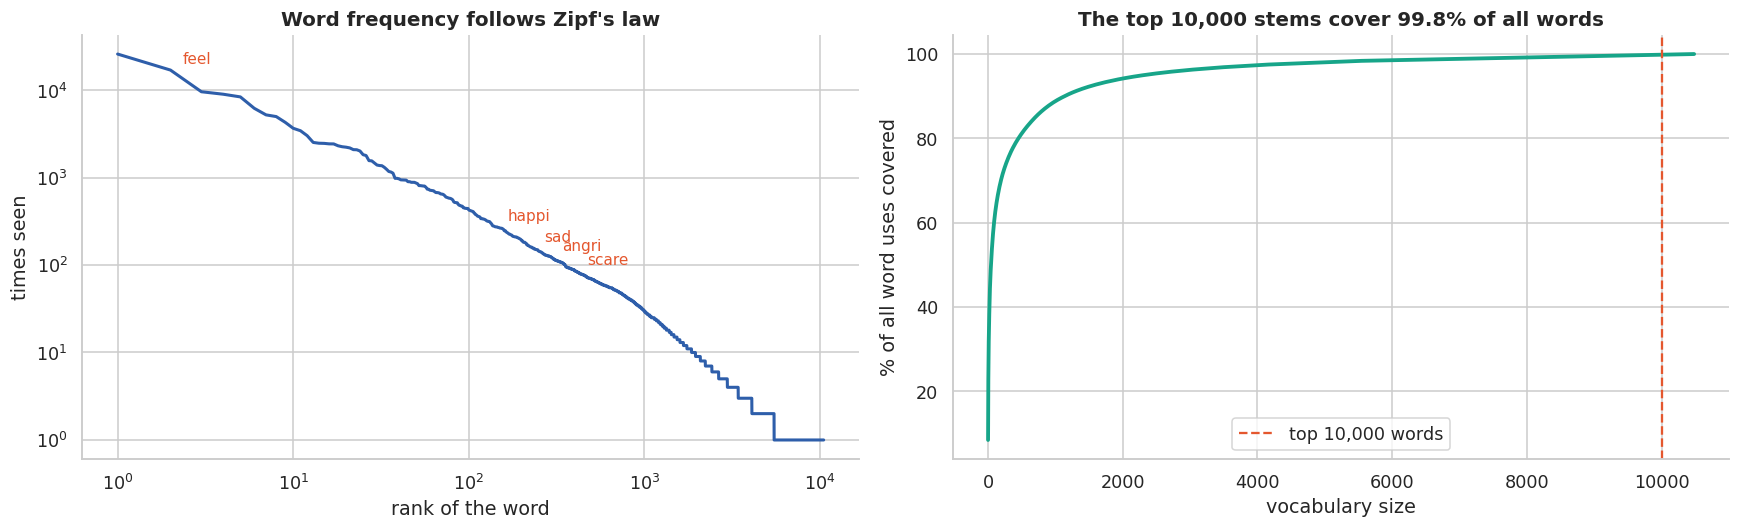

In [8]:
freq = pd.Series(tokenizer.word_counts).sort_values(ascending=False)
coverage = freq.cumsum() / freq.sum()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].loglog(np.arange(1, len(freq) + 1), freq.values, color='#2E5EAA', lw=2)
axes[0].set_title("Word frequency follows Zipf's law")
axes[0].set_xlabel('rank of the word'); axes[0].set_ylabel('times seen')
for w in ['feel', 'happi', 'sad', 'angri', 'scare']:
    if w in freq.index:
        r = freq.index.get_loc(w) + 1
        axes[0].annotate(w, (r, freq[w]), xytext=(8, 4), textcoords='offset points', fontsize=10, color='#E4572E')

axes[1].plot(np.arange(1, len(coverage) + 1), coverage.values * 100, color='#17A589', lw=2.5)
axes[1].axvline(MAX_WORDS, color='#E4572E', ls='--', label=f'top {MAX_WORDS:,} words')
axes[1].set_title(f'The top {MAX_WORDS:,} stems cover {coverage.iloc[MAX_WORDS-1]:.1%} of all words')
axes[1].set_xlabel('vocabulary size'); axes[1].set_ylabel('% of all word uses covered')
axes[1].legend()
plt.tight_layout(); plt.show()

### Class weights

To stop the model from ignoring rare emotions, examples of rare emotions get a larger weight in the loss.
Full inverse-frequency weights push too hard (the model then calls many sentences *surprise* to avoid
missing any), so we **soften them with a square root**: rare emotions get more attention, without the model
over-predicting them.

In [9]:
weights = np.sqrt(compute_class_weight('balanced', classes=np.arange(NUM_CLASSES), y=y_train))
class_weight = dict(enumerate(weights))
pd.DataFrame({'emotion': EMOTIONS, 'examples': np.bincount(y_train), 'weight': weights.round(2)}).set_index('emotion').T

emotion,sadness,joy,love,anger,fear,surprise
examples,4663.00,5345.00,1293.00,2155.00,1930.00,567.00
weight,0.76,0.71,1.43,1.11,1.17,2.17


---
## 5. Model Architectures

We start with a **classic machine learning baseline**, then four deep learning models. Every deep model
begins with an **embedding layer**: it learns a 128-number vector for each word, so that words used in
similar ways end up close together.

| Model | How it reads a sentence |
|---|---|
| **TF-IDF + Logistic Regression** | Counts words and word pairs, weighs rare telling words higher, draws straight boundaries between emotions. Fast and strong, the bar to beat. |
| **Bi-LSTM** | Reads word by word, forwards *and* backwards, remembering what came before. Good at context like *"not happy"*. |
| **1D CNN** | Slides filters over groups of 3, 4 and 5 words to spot phrases like *"so angry"*, wherever they appear. |
| **Hybrid CNN-LSTM** | CNN finds the phrases, then an LSTM reads them in order. |
| **Attention Bi-LSTM** | A Bi-LSTM that also learns *which words to focus on*. We can look at that focus to see why it decided. |
| **RoBERTa** | A Transformer already trained on about 160 GB of English text, then fine-tuned on our emotions (Section 7). |

In [10]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
Xtf_train = tfidf.fit_transform(train_data['stemmed'])
Xtf_val, Xtf_test = tfidf.transform(val_data['stemmed']), tfidf.transform(test_data['stemmed'])

logreg = LogisticRegression(C=8, max_iter=3000)
logreg.fit(Xtf_train, y_train)
print(f'TF-IDF features: {Xtf_train.shape[1]:,}')
print(f'Baseline validation accuracy: {accuracy_score(y_val, logreg.predict(Xtf_val)):.4f}')

TF-IDF features: 30,878
Baseline validation accuracy: 0.8607


In [11]:
EMBEDDING_DIM = 128


def build_lstm_model():
    return Sequential([
        layers.Input(shape=(MAX_LEN,)),
        layers.Embedding(MAX_WORDS, EMBEDDING_DIM),
        layers.Bidirectional(layers.LSTM(128, return_sequences=True)),
        layers.Dropout(0.3),
        layers.Bidirectional(layers.LSTM(64)),
        layers.Dropout(0.3),
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(NUM_CLASSES, activation='softmax'),
    ], name='bi_lstm')


def build_cnn_model():
    inp = layers.Input(shape=(MAX_LEN,))
    emb = layers.SpatialDropout1D(0.2)(layers.Embedding(MAX_WORDS, EMBEDDING_DIM)(inp))
    pooled = [layers.GlobalMaxPooling1D()(layers.Conv1D(128, k, activation='relu')(emb)) for k in (3, 4, 5)]
    x = layers.Dropout(0.5)(layers.Concatenate()(pooled))
    x = layers.Dropout(0.3)(layers.Dense(64, activation='relu')(x))
    return Model(inp, layers.Dense(NUM_CLASSES, activation='softmax')(x), name='cnn')


def build_hybrid_model():
    return Sequential([
        layers.Input(shape=(MAX_LEN,)),
        layers.Embedding(MAX_WORDS, EMBEDDING_DIM),
        layers.Conv1D(128, 5, activation='relu', padding='same'),
        layers.MaxPooling1D(2),
        layers.Dropout(0.3),
        layers.Bidirectional(layers.LSTM(64)),
        layers.Dropout(0.3),
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(NUM_CLASSES, activation='softmax'),
    ], name='hybrid_cnn_lstm')


class Attention(layers.Layer):
    def build(self, shape):
        self.W = self.add_weight(name='W', shape=(shape[-1], 64), initializer='glorot_uniform')
        self.v = self.add_weight(name='v', shape=(64, 1), initializer='glorot_uniform')

    def call(self, h, mask=None):
        score = tf.squeeze(tf.matmul(tf.tanh(tf.matmul(h, self.W)), self.v), -1)
        if mask is not None:
            score += (1.0 - tf.cast(mask, score.dtype)) * -1e9
        alpha = tf.nn.softmax(score, axis=1)
        return tf.reduce_sum(h * tf.expand_dims(alpha, -1), axis=1), alpha

    def compute_mask(self, inputs, mask=None):
        return None


def build_attention_model():
    inp = layers.Input(shape=(MAX_LEN,))
    emb = layers.Embedding(MAX_WORDS, EMBEDDING_DIM, mask_zero=True)(inp)
    h = layers.Bidirectional(layers.LSTM(96, return_sequences=True))(emb)
    h = layers.Dropout(0.3)(h)
    context, alpha = Attention(name='attention')(h)
    x = layers.Dropout(0.3)(layers.Dense(64, activation='relu')(context))
    out = layers.Dense(NUM_CLASSES, activation='softmax')(x)
    return Model(inp, out, name='attention_bi_lstm'), Model(inp, alpha)


lstm_model = build_lstm_model()
cnn_model = build_cnn_model()
hybrid_model = build_hybrid_model()
attention_model, attention_reader = build_attention_model()

deep_models = {'Bi-LSTM': lstm_model, 'CNN': cnn_model, 'Hybrid CNN-LSTM': hybrid_model,
               'Attention Bi-LSTM': attention_model}
pd.DataFrame({'trainable parameters': {n: f'{m.count_params():,}' for n, m in deep_models.items()},
              'layers': {n: len(m.layers) for n, m in deep_models.items()}})

,trainable parameters,layers
Bi-LSTM,"1,716,166",8
CNN,"1,502,022",14
Hybrid CNN-LSTM,"1,469,510",9
Attention Bi-LSTM,"1,477,894",8


---
## 6. Compile Models

* **Loss:** categorical cross-entropy, the standard loss for picking one class out of several.
* **Optimizer:** Adam with learning rate 0.001.
* **Early stopping:** stop when validation loss has not improved for 3 epochs, and roll back to the best
  epoch, so the model does not start memorising the training data.
* **Learning rate schedule:** halve the learning rate when progress stalls, for finer final steps.

In [12]:
for name, model in deep_models.items():
    model.compile(loss='categorical_crossentropy', optimizer=Adam(learning_rate=1e-3), metrics=['accuracy'])
    print(f'{name:18s} compiled')


def callbacks():
    return [EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
            ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=0)]

Bi-LSTM            compiled
CNN                compiled
Hybrid CNN-LSTM    compiled
Attention Bi-LSTM  compiled


---
## 7. Train Models

Each model trains for up to 20 passes over the data (epochs), in batches of 64 sentences, with the class
weights from step 4. Early stopping usually ends training much sooner.

In [13]:
import time
EPOCHS, BATCH_SIZE = 20, 64
histories, train_time = {}, {}

for name, model in deep_models.items():
    start = time.time()
    hist = model.fit(X_train, y_train_cat, validation_data=(X_val, y_val_cat), epochs=EPOCHS,
                     batch_size=BATCH_SIZE, class_weight=class_weight, callbacks=callbacks(), verbose=0)
    histories[name] = hist.history
    train_time[name] = time.time() - start
    best = int(np.argmin(hist.history['val_loss']))
    print(f"{name:18s} {len(hist.history['loss']):2d} epochs in {train_time[name]/60:4.1f} min   "
          f"best epoch {best+1}: val accuracy {hist.history['val_accuracy'][best]:.4f}")

Bi-LSTM             7 epochs in  0.7 min   best epoch 4: val accuracy 0.8973


CNN                 5 epochs in  0.3 min   best epoch 2: val accuracy 0.9080
Hybrid CNN-LSTM     5 epochs in  0.3 min   best epoch 2: val accuracy 0.8887
Attention Bi-LSTM   5 epochs in  0.3 min   best epoch 2: val accuracy 0.9027


### Model 6: RoBERTa, a pre-trained Transformer

Every model above learns English from our 16,000 tweets alone. **RoBERTa** has already read about 160 GB of
English text (books, news, web pages) and learned how words relate to each other. We only **fine-tune**
it: put a small classifier on top and gently train the whole network (learning rate 0.00002) on our
emotions for a few epochs. This is **transfer learning**, the standard way to get top results in NLP.

A Transformer reads all words at once and lets every word look at every other word (*self-attention*),
so it understands context like *"not happy"* or *"happy for her but"* better than models that read left
to right. It uses its own tokenizer, which splits rare words into known pieces, so it gets the cleaned
text without stemming. The same softened class weights are used.

It needs a GPU: a few minutes on Kaggle's free GPU, versus well over an hour on a CPU.

In [14]:
import torch
from torch.utils.data import DataLoader, TensorDataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
CHECKPOINT, RB_EPOCHS, RB_BATCH, RB_LEN = 'roberta-base', 4, 32, 96
torch.manual_seed(SEED)

rb_tokenizer = AutoTokenizer.from_pretrained(CHECKPOINT)


def rb_loader(texts, labels=None, shuffle=False):
    enc = rb_tokenizer(list(texts), padding='max_length', truncation=True, max_length=RB_LEN, return_tensors='pt')
    tensors = [enc['input_ids'], enc['attention_mask']]
    if labels is not None:
        tensors.append(torch.tensor(labels))
    return DataLoader(TensorDataset(*tensors), batch_size=RB_BATCH, shuffle=shuffle)


@torch.no_grad()
def rb_probs(loader):
    roberta.eval()
    out = []
    for batch in loader:
        with torch.autocast(DEVICE.type, enabled=DEVICE.type == 'cuda'):
            logits = roberta(input_ids=batch[0].to(DEVICE), attention_mask=batch[1].to(DEVICE)).logits
        out.append(torch.softmax(logits.float(), -1).cpu().numpy())
    return np.concatenate(out)


train_dl = rb_loader(train_data['clean'], y_train, shuffle=True)
val_dl, test_dl = rb_loader(val_data['clean']), rb_loader(test_data['clean'])

roberta = AutoModelForSequenceClassification.from_pretrained(CHECKPOINT, num_labels=NUM_CLASSES).to(DEVICE)
optimizer = torch.optim.AdamW(roberta.parameters(), lr=2e-5, weight_decay=0.01)
steps = len(train_dl) * RB_EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * steps), steps)
loss_fn = torch.nn.CrossEntropyLoss(weight=torch.tensor(weights, dtype=torch.float32, device=DEVICE))
scaler = torch.amp.GradScaler(enabled=DEVICE.type == 'cuda')

h = {'accuracy': [], 'val_accuracy': [], 'loss': [], 'val_loss': []}
best_state, best_loss, start = None, np.inf, time.time()
for epoch in range(RB_EPOCHS):
    roberta.train()
    seen = correct = total = 0.0
    for ids, mask, y in train_dl:
        ids, mask, y = ids.to(DEVICE), mask.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        with torch.autocast(DEVICE.type, enabled=DEVICE.type == 'cuda'):
            logits = roberta(input_ids=ids, attention_mask=mask).logits
        loss = loss_fn(logits.float(), y)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(roberta.parameters(), 1.0)
        scaler.step(optimizer); scaler.update(); scheduler.step()
        total += loss.item() * len(y); correct += (logits.argmax(1) == y).sum().item(); seen += len(y)

    p_val = rb_probs(val_dl)
    val_loss = float(-np.log(p_val[np.arange(len(y_val)), y_val] + 1e-9).mean())
    h['loss'].append(total / seen); h['accuracy'].append(correct / seen)
    h['val_loss'].append(val_loss); h['val_accuracy'].append(accuracy_score(y_val, p_val.argmax(1)))
    if val_loss < best_loss:
        best_loss = val_loss
        best_state = {k: v.detach().cpu().clone() for k, v in roberta.state_dict().items()}
    print(f'epoch {epoch + 1}: train accuracy {h["accuracy"][-1]:.4f}   '
          f'val accuracy {h["val_accuracy"][-1]:.4f}   val loss {val_loss:.4f}')

roberta.load_state_dict(best_state)
histories['RoBERTa'] = h
train_time['RoBERTa'] = time.time() - start
print(f'RoBERTa: {train_time["RoBERTa"] / 60:.1f} min on {DEVICE.type.upper()}, '
      f'kept epoch {int(np.argmin(h["val_loss"])) + 1}')

epoch 1: train accuracy 0.6982   val accuracy 0.9113   val loss 0.2516
epoch 2: train accuracy 0.9231   val accuracy 0.9283   val loss 0.1772
epoch 3: train accuracy 0.9395   val accuracy 0.9317   val loss 0.1597
epoch 4: train accuracy 0.9501   val accuracy 0.9313   val loss 0.1569
RoBERTa: 6.1 min on CUDA, kept epoch 4


---
## 8. Evaluation

The 1,000 test sentences were never used for training or for any decision. We report:

* **Accuracy:** share of sentences labelled correctly.
* **Macro F1:** average F1 over the six emotions, so rare emotions count as much as common ones.
* **Cohen's kappa:** agreement with the true labels after removing agreement expected by chance.

In [15]:
probs = {'TF-IDF + LogReg': logreg.predict_proba(Xtf_test)}
val_probs = {'TF-IDF + LogReg': logreg.predict_proba(Xtf_val)}
for name, model in deep_models.items():
    probs[name] = model.predict(X_test, verbose=0)
    val_probs[name] = model.predict(X_val, verbose=0)
probs['RoBERTa'], val_probs['RoBERTa'] = rb_probs(test_dl), rb_probs(val_dl)
preds = {n: p.argmax(1) for n, p in probs.items()}


def scores(y, p):
    return {'Accuracy': accuracy_score(y, p), 'Macro F1': f1_score(y, p, average='macro'),
            'Weighted F1': f1_score(y, p, average='weighted'), 'Kappa': cohen_kappa_score(y, p)}


results = pd.DataFrame({n: scores(y_test, p) for n, p in preds.items()}).T
results['Train minutes'] = pd.Series(train_time) / 60
results = results.sort_values('Macro F1', ascending=False)
(results.style.format({'Accuracy': '{:.4f}', 'Macro F1': '{:.4f}', 'Weighted F1': '{:.4f}',
                       'Kappa': '{:.4f}', 'Train minutes': '{:.1f}'}, na_rep='< 0.1')
        .background_gradient(subset=['Accuracy', 'Macro F1'], cmap='Greens'))

,Accuracy,Macro F1,Weighted F1,Kappa,Train minutes
RoBERTa,0.9320,0.8964,0.9334,0.9112,6.1
Attention Bi-LSTM,0.8930,0.8419,0.8932,0.8586,0.3
Bi-LSTM,0.8900,0.8414,0.8918,0.8557,0.7
CNN,0.8910,0.8405,0.8940,0.8576,0.3
Hybrid CNN-LSTM,0.8820,0.8289,0.8833,0.8447,0.3
TF-IDF + LogReg,0.8450,0.7828,0.8405,0.7924,< 0.1


---
## 9. Visualization: Learning Curves

How did accuracy and loss change during training? A growing gap between training and validation means
the model is starting to memorise. The dot marks the epoch that was kept.

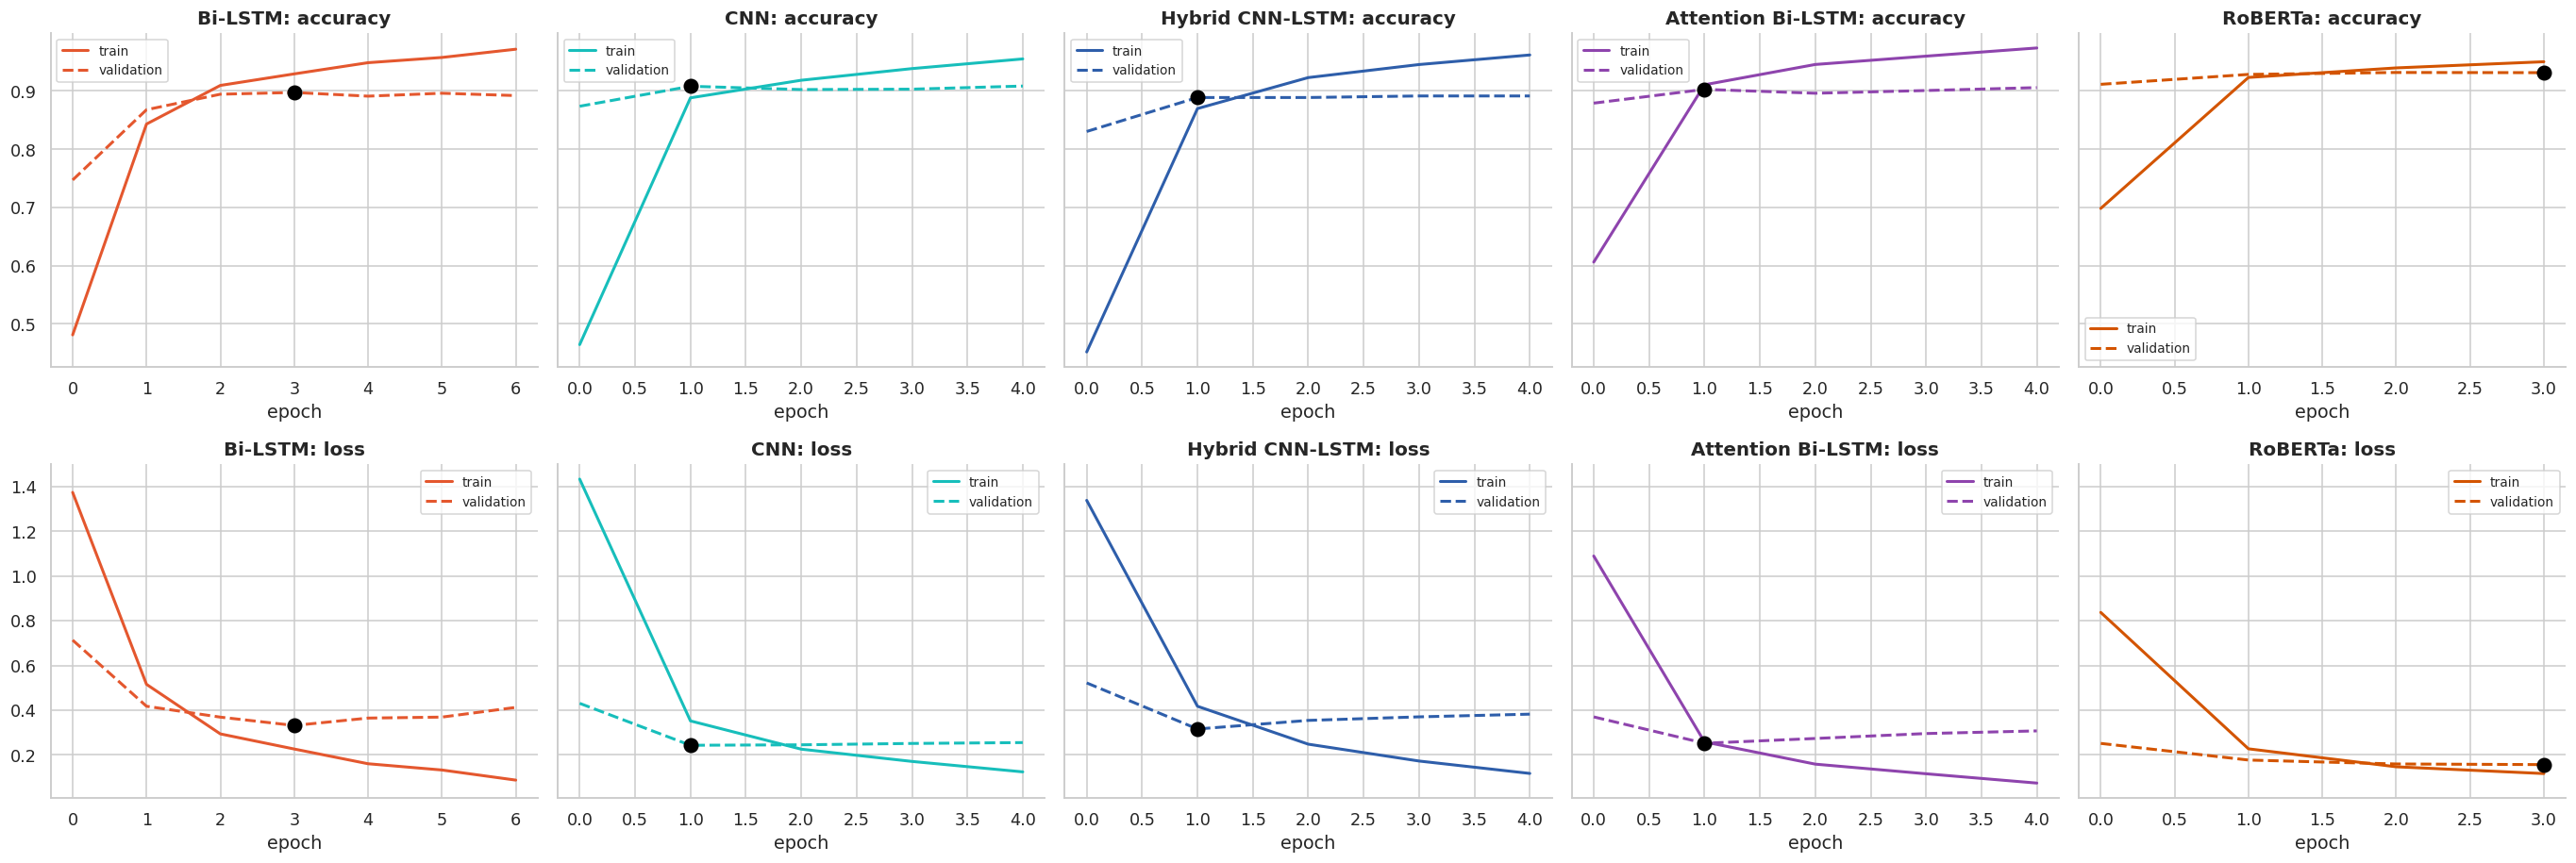

In [16]:
fig, axes = plt.subplots(2, len(histories), figsize=(5 * len(histories), 8.5), sharey='row')
for col, (name, h) in enumerate(histories.items()):
    best = int(np.argmin(h['val_loss']))
    for row, metric in enumerate(['accuracy', 'loss']):
        ax = axes[row, col]
        ax.plot(h[metric], color=MODEL_COLORS[name], lw=2, label='train')
        ax.plot(h[f'val_{metric}'], color=MODEL_COLORS[name], lw=2, ls='--', label='validation')
        ax.scatter(best, h[f'val_{metric}'][best], s=90, color='black', zorder=3)
        ax.set_title(f'{name}: {metric}'); ax.set_xlabel('epoch')
        ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

---
## 10. Model Comparison

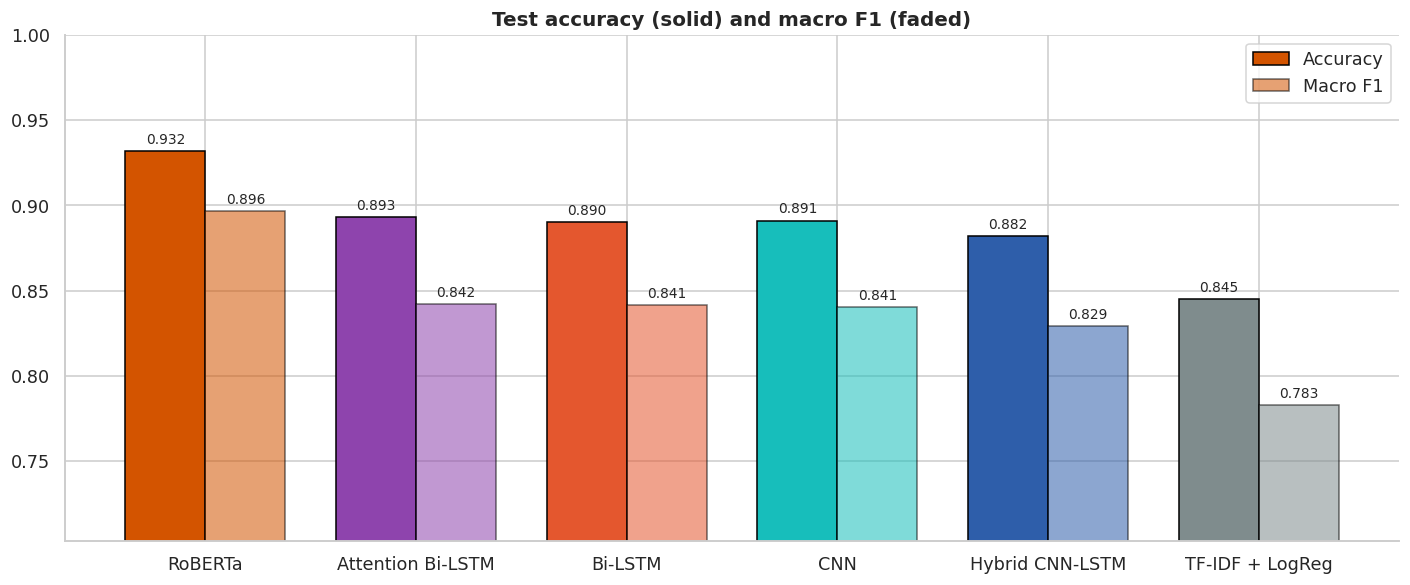

In [17]:
fig, ax = plt.subplots(figsize=(13, 5.5))
x = np.arange(len(results))
for i, (metric, shade) in enumerate([('Accuracy', 1.0), ('Macro F1', 0.55)]):
    bars = ax.bar(x + (i - 0.5) * 0.38, results[metric], width=0.38, alpha=shade,
                  color=[MODEL_COLORS[n] for n in results.index], edgecolor='black', label=metric)
    ax.bar_label(bars, labels=[f'{v:.3f}' for v in results[metric]], padding=3, fontsize=9)
ax.set_xticks(x, results.index)
ax.set_ylim(results[['Accuracy', 'Macro F1']].min().min() - 0.08, 1.0)
ax.set_title('Test accuracy (solid) and macro F1 (faded)')
ax.legend()
plt.tight_layout(); plt.show()

---
## 11. Confusion Matrices

Rows are the true emotion, columns the predicted one, and each row adds up to 100%. The diagonal is
what we got right.

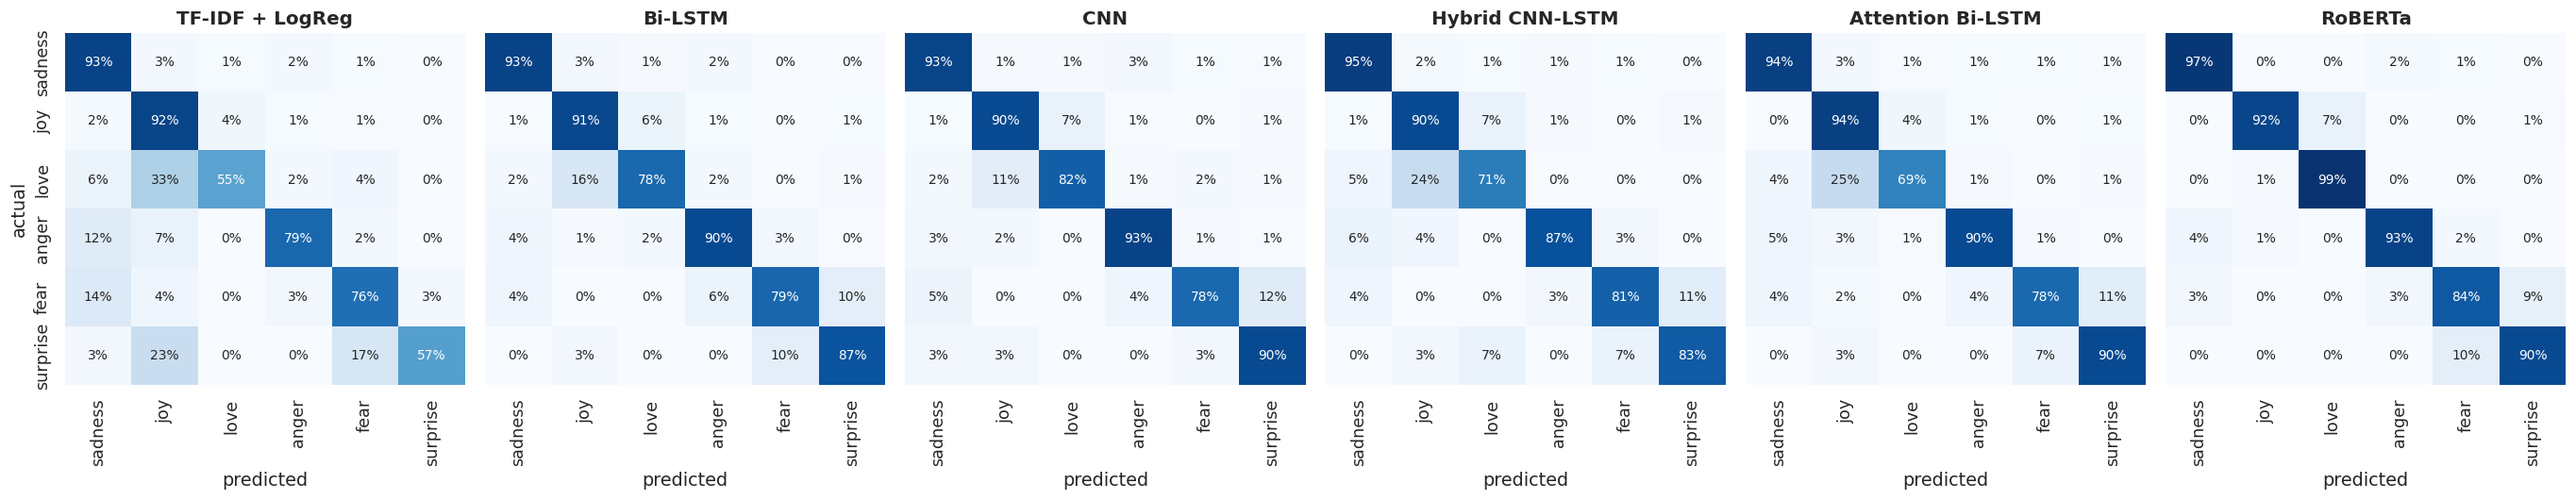

In [18]:
fig, axes = plt.subplots(1, len(preds), figsize=(25, 5))
for ax, (name, p) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, p, normalize='true')
    sns.heatmap(cm, annot=True, fmt='.0%', cmap='Blues', cbar=False, ax=ax, vmin=0, vmax=1,
                xticklabels=EMOTIONS, yticklabels=EMOTIONS if ax is axes[0] else False,
                annot_kws={'fontsize': 9})
    ax.set_title(name); ax.set_xlabel('predicted')
axes[0].set_ylabel('actual')
plt.tight_layout(); plt.show()

---
## 12. Classification Reports

Precision: when the model says *love*, how often is it love? Recall: of all the real *love* sentences,
how many did it find? F1 balances the two.

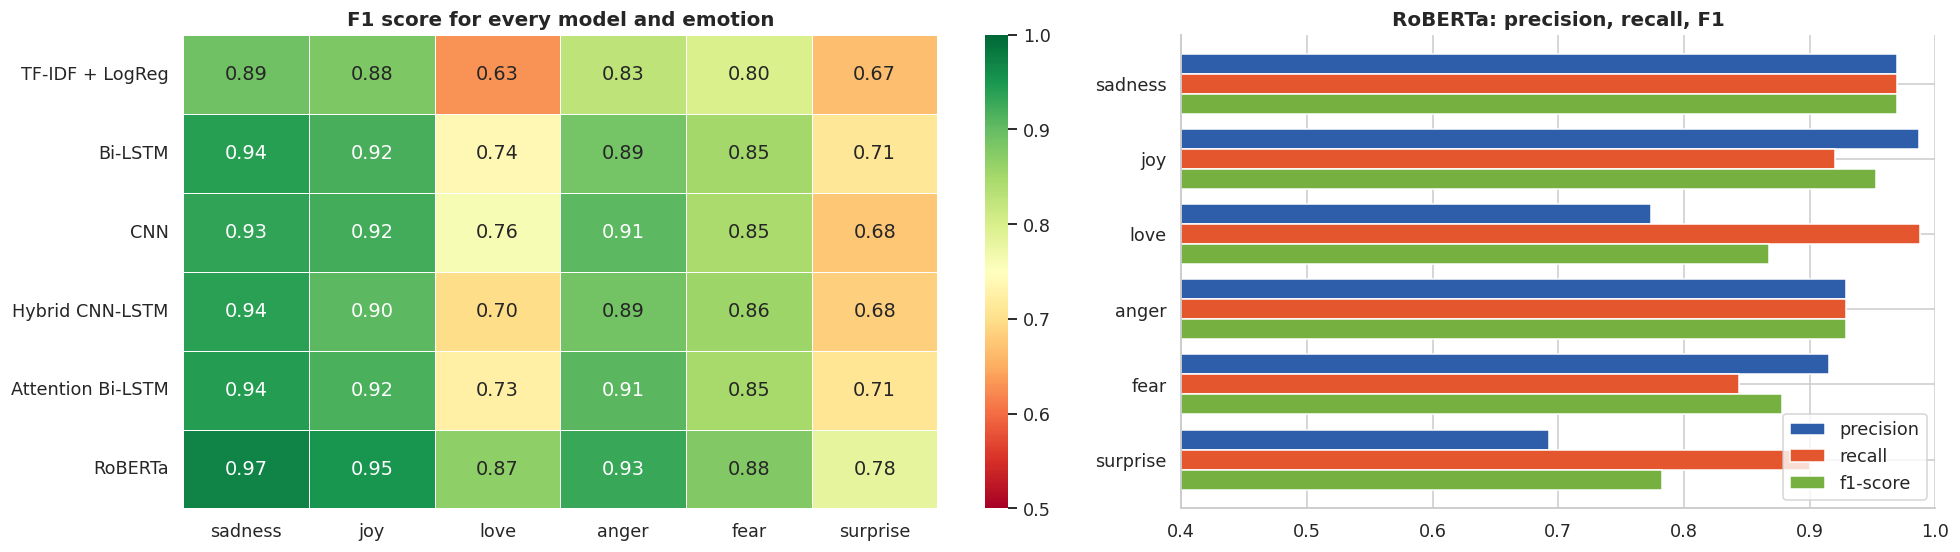

              precision    recall  f1-score   support

     sadness      0.969     0.969     0.969       295
         joy      0.987     0.920     0.952       337
        love      0.774     0.988     0.868        83
       anger      0.929     0.929     0.929       140
        fear      0.915     0.843     0.878       115
    surprise      0.692     0.900     0.783        30

    accuracy                          0.932      1000
   macro avg      0.878     0.925     0.896      1000
weighted avg      0.939     0.932     0.933      1000



In [19]:
f1_table = pd.DataFrame({n: f1_score(y_test, p, average=None) for n, p in preds.items()}, index=EMOTIONS)

fig, axes = plt.subplots(1, 2, figsize=(18, 5.2), gridspec_kw={'width_ratios': [1.25, 1]})
sns.heatmap(f1_table.T, annot=True, fmt='.2f', cmap='RdYlGn', vmin=0.5, vmax=1, ax=axes[0],
            linewidths=0.5)
axes[0].set_title('F1 score for every model and emotion')

best_single = results.index[0]
rep = pd.DataFrame(classification_report(y_test, preds[best_single], target_names=EMOTIONS,
                                         output_dict=True)).T.loc[EMOTIONS, ['precision', 'recall', 'f1-score']]
rep.plot.barh(ax=axes[1], color=['#2E5EAA', '#E4572E', '#76B041'], width=0.8)
axes[1].set_xlim(0.4, 1.0); axes[1].invert_yaxis()
axes[1].set_title(f'{best_single}: precision, recall, F1')
axes[1].legend(loc='lower right')
plt.tight_layout(); plt.show()

print(classification_report(y_test, preds[best_single], target_names=EMOTIONS, digits=3))

**What we see:** *sadness, joy* and *anger* are easy, every model gets them right most of the time.
*Love* and *surprise* are the hardest: they are rare in the data, and *love* sentences often sound like
*joy* (*"i feel so lucky to have him"*), while *surprise* overlaps with *fear* (*"i feel shocked"*).

---
## Ensemble Methods

Different models make different mistakes, so combining them can beat any one of them. We try five ways.
**Weights and the stacking meta-model are learned on the validation set**, never on the test set, so the
test score stays honest.

| Method | How it combines the models |
|---|---|
| Hard voting | Each model votes for one emotion, the majority wins |
| Soft voting | Average the predicted probabilities |
| Weighted voting | Like soft voting, but better models (on validation) count more |
| Max confidence | Trust whichever model is most sure about this sentence |
| Stacking | A logistic regression learns how to combine all the models' probabilities |

Since every weight is learned on validation, the five methods can be compared fairly on the test set.

In [20]:
members = list(probs)
P_test = np.stack([probs[m] for m in members])
P_val = np.stack([val_probs[m] for m in members])

hard = np.array([np.bincount(col, minlength=NUM_CLASSES).argmax() for col in P_test.argmax(2).T])
soft = P_test.mean(0).argmax(1)
val_acc = np.array([accuracy_score(y_val, val_probs[m].argmax(1)) for m in members])
w = np.exp((val_acc - val_acc.max()) * 100); w /= w.sum()
weighted = np.tensordot(w, P_test, axes=1).argmax(1)
maxconf = P_test.max(2).argmax(0)
maxconf = P_test.argmax(2)[maxconf, np.arange(P_test.shape[1])]

meta = LogisticRegression(C=1.0, max_iter=3000)
meta.fit(np.hstack(P_val), y_val)
stack_proba = meta.predict_proba(np.hstack(P_test))
stacking = stack_proba.argmax(1)

ensembles = {'Hard voting': hard, 'Soft voting': soft, 'Weighted voting': weighted,
             'Max confidence': maxconf, 'Stacking': stacking}
ens_results = pd.DataFrame({n: scores(y_test, p) for n, p in ensembles.items()}).T
all_results = pd.concat([results.drop(columns='Train minutes').assign(Type='single model'),
                         ens_results.assign(Type='ensemble')]).sort_values('Macro F1', ascending=False)
print('Weights learned from validation accuracy:', dict(zip(members, w.round(3))))
all_results.style.format({c: '{:.4f}' for c in ['Accuracy', 'Macro F1', 'Weighted F1', 'Kappa']}) \
    .background_gradient(subset=['Macro F1'], cmap='Greens')

Weights learned from validation accuracy: {'TF-IDF + LogReg': np.float64(0.001), 'Bi-LSTM': np.float64(0.028), 'CNN': np.float64(0.081), 'Hybrid CNN-LSTM': np.float64(0.012), 'Attention Bi-LSTM': np.float64(0.047), 'RoBERTa': np.float64(0.832)}


,Accuracy,Macro F1,Weighted F1,Kappa,Type
Weighted voting,0.9330,0.8982,0.9344,0.9125,ensemble
RoBERTa,0.9320,0.8964,0.9334,0.9112,single model
Stacking,0.9290,0.8840,0.9292,0.9064,ensemble
Max confidence,0.9200,0.8770,0.9210,0.8949,ensemble
Soft voting,0.9050,0.8609,0.9060,0.8751,ensemble
Hard voting,0.9010,0.8559,0.9013,0.8695,ensemble
Attention Bi-LSTM,0.8930,0.8419,0.8932,0.8586,single model
Bi-LSTM,0.8900,0.8414,0.8918,0.8557,single model
CNN,0.8910,0.8405,0.8940,0.8576,single model
Hybrid CNN-LSTM,0.8820,0.8289,0.8833,0.8447,single model


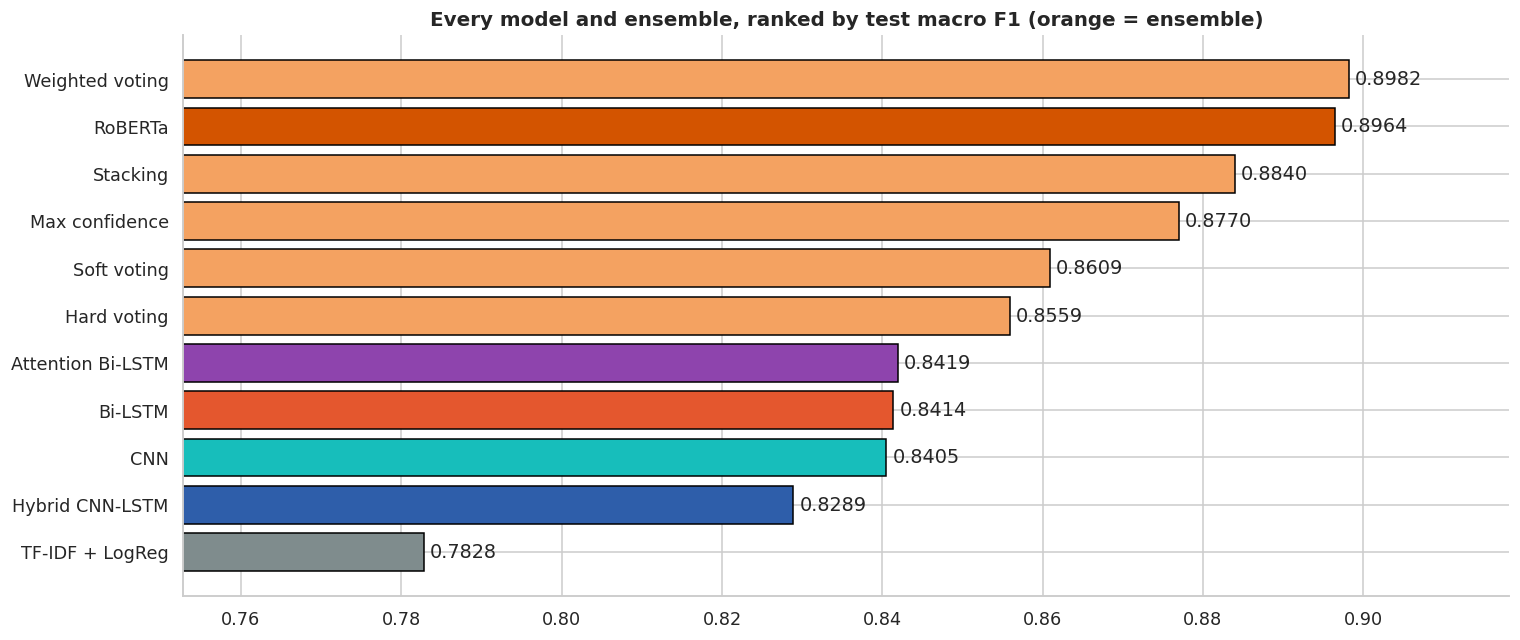

Best overall: Weighted voting  (accuracy 0.9330, macro F1 0.8982)


In [21]:
fig, ax = plt.subplots(figsize=(14, 6))
colors = [MODEL_COLORS.get(n, '#F4A261') for n in all_results.index]
bars = ax.barh(all_results.index[::-1], all_results['Macro F1'][::-1], color=colors[::-1], edgecolor='black')
ax.bar_label(bars, labels=[f'{v:.4f}' for v in all_results['Macro F1'][::-1]], padding=4)
ax.set_xlim(all_results['Macro F1'].min() - 0.03, all_results['Macro F1'].max() + 0.02)
ax.set_title('Every model and ensemble, ranked by test macro F1 (orange = ensemble)')
plt.tight_layout(); plt.show()

BEST = all_results.index[0]
best_pred = ensembles[BEST] if BEST in ensembles else preds[BEST]
best_proba = {'Stacking': stack_proba, 'Soft voting': P_test.mean(0),
              'Weighted voting': np.tensordot(w, P_test, axes=1)}.get(BEST, probs.get(BEST, P_test.mean(0)))
print(f'Best overall: {BEST}  (accuracy {all_results.loc[BEST, "Accuracy"]:.4f}, '
      f'macro F1 {all_results.loc[BEST, "Macro F1"]:.4f})')

---
## Deeper Analysis

### How sure is the model, and should we believe it?

A model that says *"90% sure"* should be right about 90% of the time. The **reliability diagram**
checks this: the closer the bars are to the diagonal, the more trustworthy the confidence. The
**expected calibration error (ECE)** sums up the gap in one number.

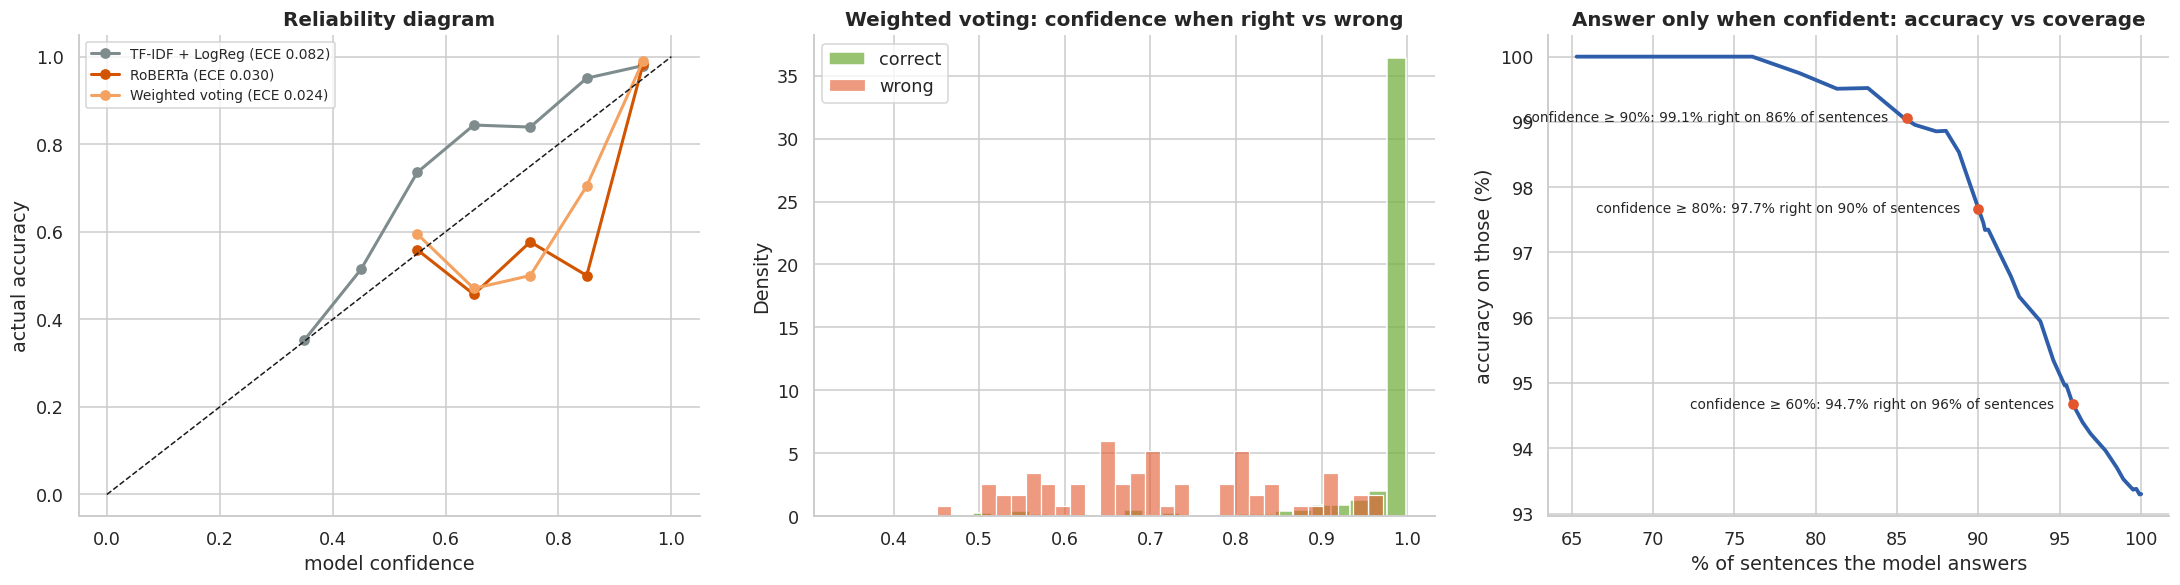

In [22]:
def reliability(proba, y, bins=10):
    conf, pred = proba.max(1), proba.argmax(1)
    edges = np.linspace(0, 1, bins + 1)
    idx = np.clip(np.digitize(conf, edges) - 1, 0, bins - 1)
    acc = np.array([(pred[idx == b] == y[idx == b]).mean() if (idx == b).any() else np.nan for b in range(bins)])
    cnt = np.bincount(idx, minlength=bins)
    ece = np.nansum(np.abs(acc - np.array([conf[idx == b].mean() if cnt[b] else 0 for b in range(bins)])) * cnt) / len(y)
    return edges, acc, cnt, ece


fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for name in ['TF-IDF + LogReg', results.index[0], BEST]:
    edges, acc, cnt, ece = reliability(probs.get(name, best_proba), y_test)
    acc = np.where(cnt >= 10, acc, np.nan)
    axes[0].plot((edges[:-1] + edges[1:]) / 2, acc, marker='o', lw=2,
                 color=MODEL_COLORS.get(name, '#F4A261'), label=f'{name} (ECE {ece:.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[0].set_xlabel('model confidence'); axes[0].set_ylabel('actual accuracy')
axes[0].set_title('Reliability diagram'); axes[0].legend(fontsize=9)

conf = best_proba.max(1); correct = best_pred == y_test
sns.histplot(conf[correct], bins=30, color='#76B041', label='correct', ax=axes[1], stat='density')
sns.histplot(conf[~correct], bins=30, color='#E4572E', label='wrong', ax=axes[1], stat='density', alpha=0.6)
axes[1].set_title(f'{BEST}: confidence when right vs wrong'); axes[1].legend()

thresholds = np.linspace(0.3, 0.99, 40)
kept = [(conf >= t).mean() for t in thresholds]
accs = [correct[conf >= t].mean() for t in thresholds]
axes[2].plot(np.array(kept) * 100, np.array(accs) * 100, color='#2E5EAA', lw=2.5)
for t in (0.6, 0.8, 0.9):
    k, a = (conf >= t).mean() * 100, correct[conf >= t].mean() * 100
    axes[2].scatter(k, a, color='#E4572E', zorder=3)
    axes[2].annotate(f'confidence ≥ {t:.0%}: {a:.1f}% right on {k:.0f}% of sentences', (k, a),
                     xytext=(-12, 0), textcoords='offset points', fontsize=9, ha='right', va='center')
axes[2].set_xlabel('% of sentences the model answers'); axes[2].set_ylabel('accuracy on those (%)')
axes[2].set_title('Answer only when confident: accuracy vs coverage')
plt.tight_layout(); plt.show()

**What we see:** RoBERTa and the ensemble are well calibrated (lowest ECE), while the TF-IDF baseline is
under-confident. The model is far less sure when it is wrong, so its confidence is useful: if it only
answers when it is at least 90% sure, it still answers more than 4 in 5 sentences and gets about 99% of
those right. The rest could go to a human. That is how such a system would be used in practice.

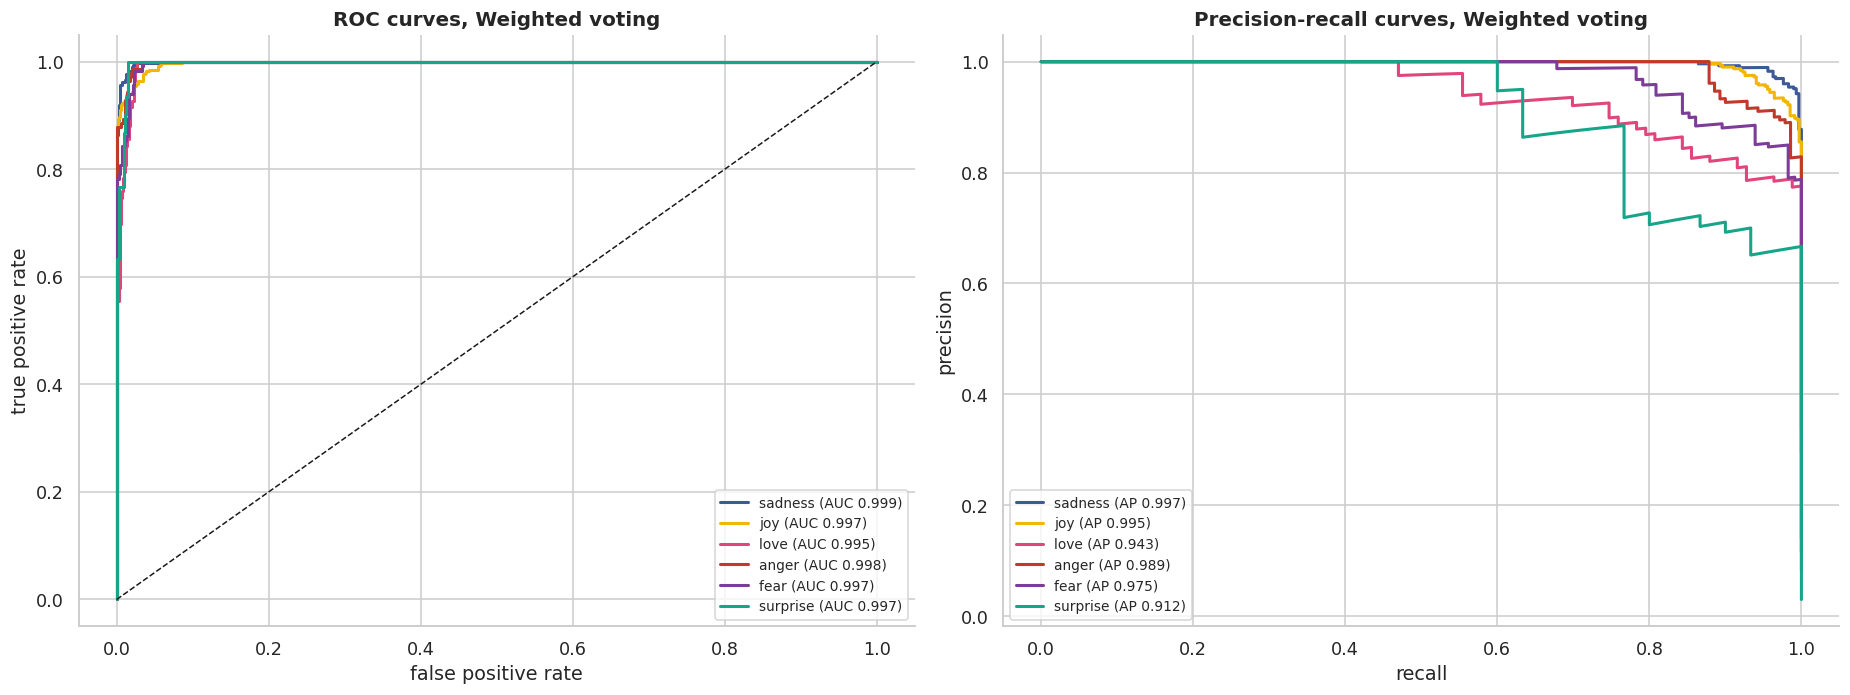

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
y_bin = to_categorical(y_test, NUM_CLASSES)
for k, emotion in enumerate(EMOTIONS):
    fpr, tpr, _ = roc_curve(y_bin[:, k], best_proba[:, k])
    axes[0].plot(fpr, tpr, lw=2, color=COLORS[emotion], label=f'{emotion} (AUC {auc(fpr, tpr):.3f})')
    prec, rec, _ = precision_recall_curve(y_bin[:, k], best_proba[:, k])
    axes[1].plot(rec, prec, lw=2, color=COLORS[emotion],
                 label=f'{emotion} (AP {average_precision_score(y_bin[:, k], best_proba[:, k]):.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[0].set_xlabel('false positive rate'); axes[0].set_ylabel('true positive rate')
axes[0].set_title(f'ROC curves, {BEST}')
axes[1].set_xlabel('recall'); axes[1].set_ylabel('precision')
axes[1].set_title(f'Precision-recall curves, {BEST}')
for ax in axes:
    ax.legend(fontsize=9, loc='lower left' if ax is axes[1] else 'lower right')
plt.tight_layout(); plt.show()

### What has the network learned? A map of sentences

We take the attention model's internal summary of each test sentence (64 numbers, the layer just
before the final decision) and squash it to 2D with **t-SNE**. Sentences the model sees as similar land
close together. Clean, separate clouds mean the network has learned emotions, not just words.

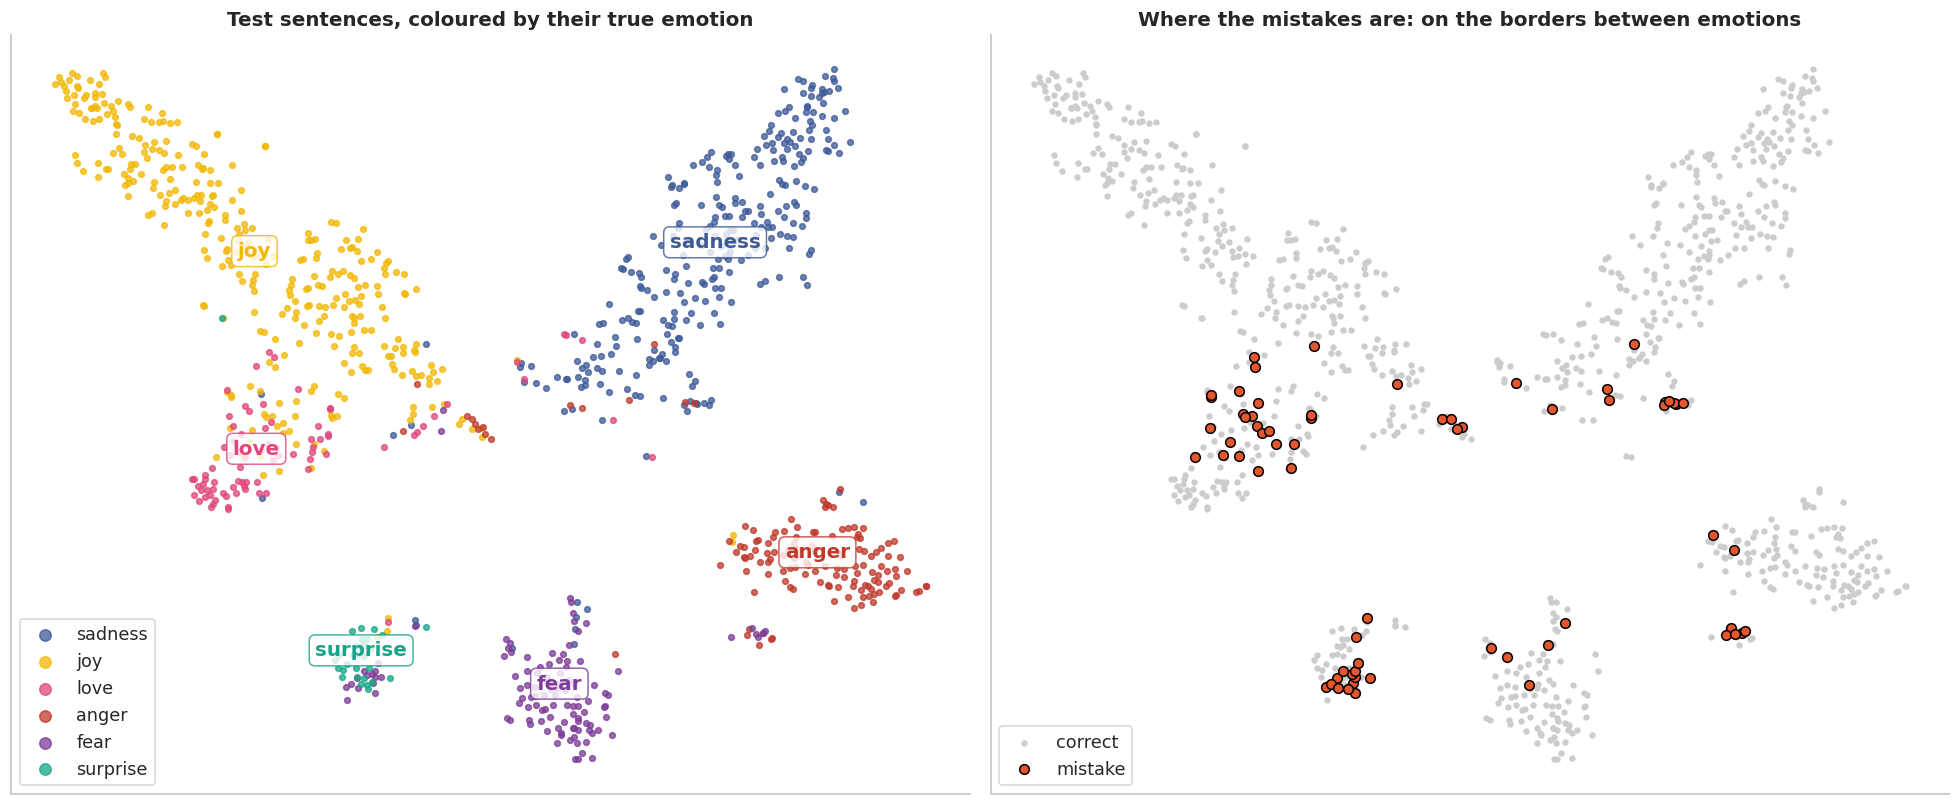

In [24]:
encoder = Model(attention_model.input, attention_model.layers[-2].output)
features = encoder.predict(X_test, verbose=0)
xy = TSNE(n_components=2, perplexity=35, random_state=SEED, init='pca').fit_transform(features)

fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
for k, emotion in enumerate(EMOTIONS):
    m = y_test == k
    axes[0].scatter(xy[m, 0], xy[m, 1], s=14, alpha=0.75, color=COLORS[emotion], label=emotion)
    cx, cy = np.median(xy[m], axis=0)
    axes[0].annotate(emotion, (cx, cy), fontsize=13, fontweight='bold', color=COLORS[emotion],
                     ha='center', bbox=dict(boxstyle='round', fc='white', alpha=0.8, ec=COLORS[emotion]))
axes[0].set_title('Test sentences, coloured by their true emotion'); axes[0].legend(markerscale=2)
wrong = best_pred != y_test
axes[1].scatter(xy[~wrong, 0], xy[~wrong, 1], s=10, color='#CCCCCC', label='correct')
axes[1].scatter(xy[wrong, 0], xy[wrong, 1], s=40, color='#E4572E', edgecolor='black', label='mistake')
axes[1].set_title('Where the mistakes are: on the borders between emotions'); axes[1].legend()
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

In [25]:
emb = cnn_model.layers[1].get_weights()[0]
emb_n = emb / (np.linalg.norm(emb, axis=1, keepdims=True) + 1e-9)
index_word = {i: w for w, i in tokenizer.word_index.items() if i < MAX_WORDS}


blocked_stems = {stemmer.stem(w) for w in BLOCKED}


def neighbours(word, k=6):
    i = tokenizer.word_index.get(stemmer.stem(word))
    if i is None or i >= MAX_WORDS:
        return []
    sims = emb_n @ emb_n[i]
    near = [index_word[j] for j in np.argsort(-sims)[1:40] if j in index_word]
    return [w for w in near if w not in blocked_stems][:k]


rows = {w: ', '.join(neighbours(w)) for w in ['happy', 'sad', 'angry', 'scared', 'amazed', 'calm']}
pd.DataFrame.from_dict(rows, orient='index', columns=['closest words in the learned embedding'])

,closest words in the learned embedding
happy,"calm, mellow, innoc, posit, privileg, wonder"
sad,"disillus, heartbroken, sorri, doom, remors, dirti"
angry,"dissatisfi, impati, hostil, jealou, heartless,..."
scared,"vulner, shi, reluct, intimid, shaken, threaten"
amazed,"funni, curiou, daze, surpris, shock, impress"
calm,"festiv, sincer, sociabl, popular, terrif, triu..."


The embedding was never told what any word means. It learned from the labels alone that, for example,
*angry* sits near other irritation words. That is the core idea of deep learning: useful representations
learned from data.

### Why did it decide that? Attention and word importance

Two ways to look inside a single prediction:

* **Attention weights** from the attention model: how much focus each word received.
* **Word occlusion**: delete one word at a time and see how much the confidence drops. A big drop means
  that word mattered.

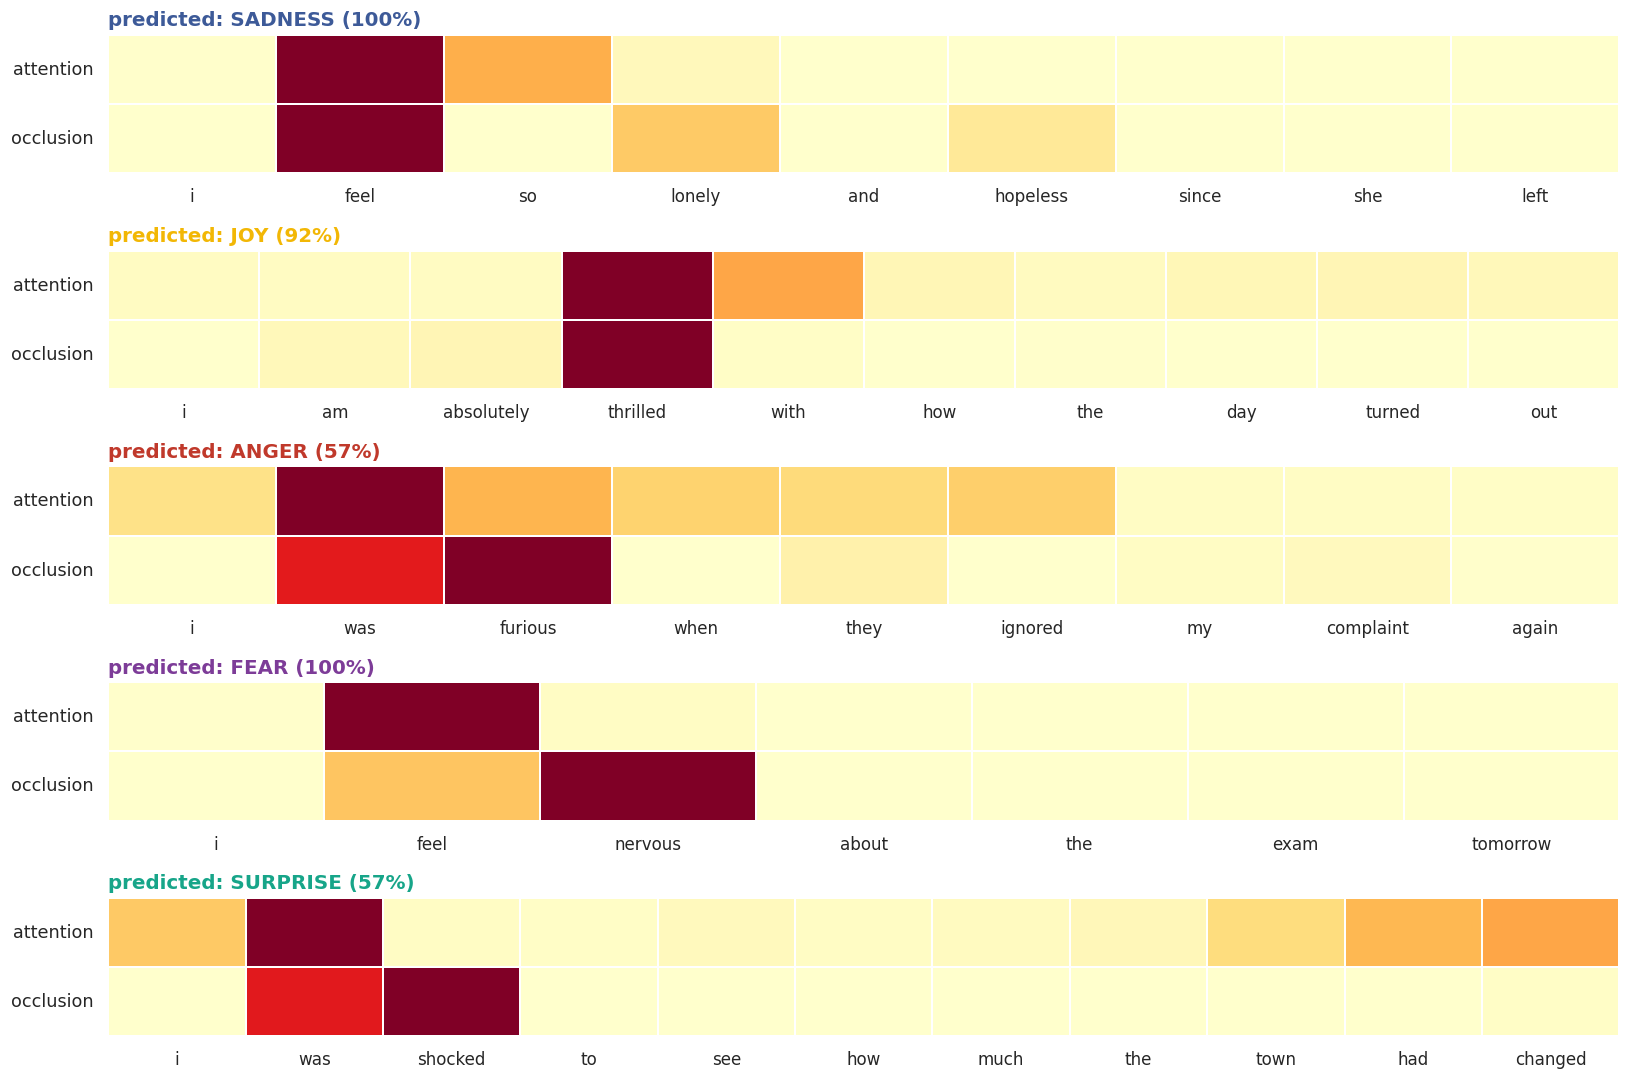

In [26]:
def explain(sentence):
    stemmed = stem_text(clean_text(sentence))
    words = stemmed.split()
    seq = to_seq([stemmed])
    p = attention_model.predict(seq, verbose=0)[0]
    k = int(p.argmax())
    att = attention_reader.predict(seq, verbose=0)[0][:len(words)]
    drops = []
    for i in range(len(words)):
        q = attention_model.predict(to_seq([' '.join(words[:i] + words[i + 1:])]), verbose=0)[0][k]
        drops.append(max(p[k] - q, 0))
    return clean_text(sentence).split()[:len(words)], np.array(att), np.array(drops), EMOTIONS[k], p[k]


samples = ['i feel so lonely and hopeless since she left',
           'i am absolutely thrilled with how the day turned out',
           'i was furious when they ignored my complaint again',
           'i feel nervous about the exam tomorrow',
           'i was shocked to see how much the town had changed']
fig, axes = plt.subplots(len(samples), 1, figsize=(15, 2.0 * len(samples)))
for ax, s in zip(axes, samples):
    words, att, drops, emotion, conf = explain(s)
    data = np.vstack([att / att.max(), drops / (drops.max() + 1e-9)])
    sns.heatmap(data, cmap='YlOrRd', cbar=False, ax=ax, xticklabels=words, yticklabels=['attention', 'occlusion'],
                annot=False, linewidths=1, linecolor='white')
    ax.set_title(f'predicted: {emotion.upper()} ({conf:.0%})', color=COLORS[emotion], loc='left')
    ax.tick_params(axis='x', rotation=0, labelsize=11); ax.tick_params(axis='y', rotation=0)
plt.tight_layout(); plt.show()

**What we see:** word occlusion is clear: the emotional words (*lonely, thrilled, furious, nervous,
shocked*) decide each prediction, and filler like *i, the, about* hardly matters. Attention also rests on
words next to them, such as *feel* and *was*. In a Bi-LSTM each position already carries the meaning of its
neighbours, so attention on *feel* in *"feel nervous"* still points at the emotion.

### Error analysis

Which emotions get mixed up most, and what do those sentences look like?

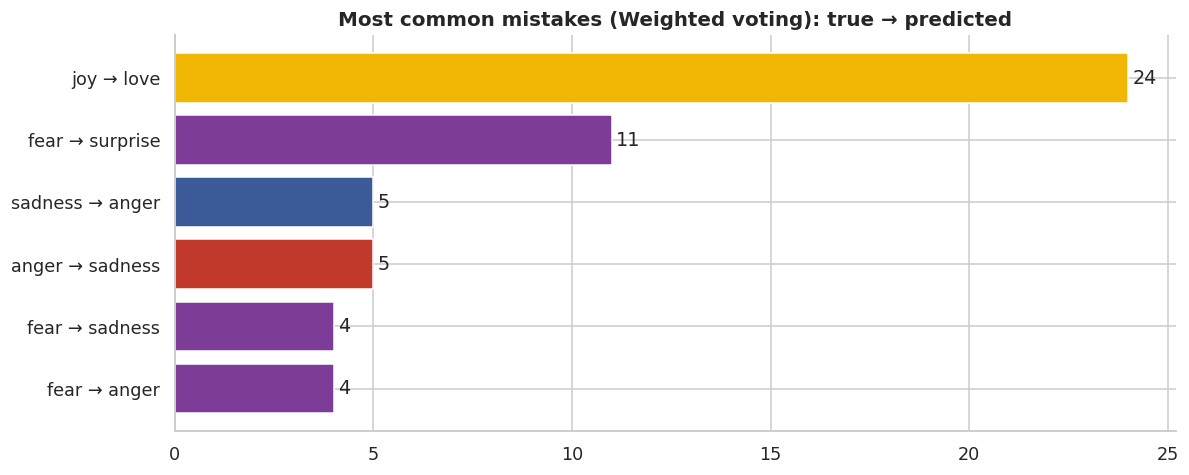

,text,true label,predicted,confidence
193,i really dont like quinn because i feel like she will just end up hurting barney and i hated the lame ted ...,anger,sadness,0.971153
426,i feel unprotected a class post count link href http reprogramming in process,sadness,fear,0.959118
845,i did feel rather like a celebrity and widget stood and let herself be admired while she drank orange squa...,joy,love,0.944621
234,i love to dance but often feel inhibited by my own body unsure what i am capable of hyper concerned about ...,fear,sadness,0.941581
419,i guess feelings aren t meant to be inhibited or prohibited,fear,sadness,0.914646
816,whenever i put myself in others shoes and try to make the person happy,anger,joy,0.905955
353,i could feel his breath on me and smell the sweet scent of him,joy,love,0.904050
496,i never feel like im not supporting,joy,love,0.903401
639,i feel more faithful than ever,joy,love,0.894820
468,i cant help feeling this way,sadness,joy,0.868623


In [27]:
cm = confusion_matrix(y_test, best_pred)
pairs = [(EMOTIONS[i], EMOTIONS[j], cm[i, j]) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j]
pairs = sorted(pairs, key=lambda t: -t[2])[:6]

fig, ax = plt.subplots(figsize=(11, 4.5))
labels = [f'{a} → {b}' for a, b, _ in pairs]
bars = ax.barh(labels[::-1], [c for *_, c in pairs][::-1], color=[COLORS[a] for a, _, _ in pairs][::-1])
ax.bar_label(bars, padding=3)
ax.set_title(f'Most common mistakes ({BEST}): true → predicted')
plt.tight_layout(); plt.show()

errors = test_data.assign(predicted=[EMOTIONS[i] for i in best_pred], confidence=best_proba.max(1))
errors = errors[errors['emotion'] != errors['predicted']].sort_values('confidence', ascending=False)
errors = errors[~errors['text'].apply(lambda t: bool(set(clean_words(t)) & BLOCKED))]
pd.set_option('display.max_colwidth', 110)
errors[['text', 'emotion', 'predicted', 'confidence']].head(10).rename(columns={'emotion': 'true label'})

Reading the confident mistakes shows that many are **debatable labels**, not model failures:
*"i feel more faithful than ever"* is labelled joy, but the model's answer, love, is at least as fair. The dataset was labelled
automatically from hashtags, so some noise is expected, and no model can be right where the label is
uncertain.

---
## 13. Prediction Examples: try the model

The final system: give it any sentence and it returns the emotion with the probability of each one.

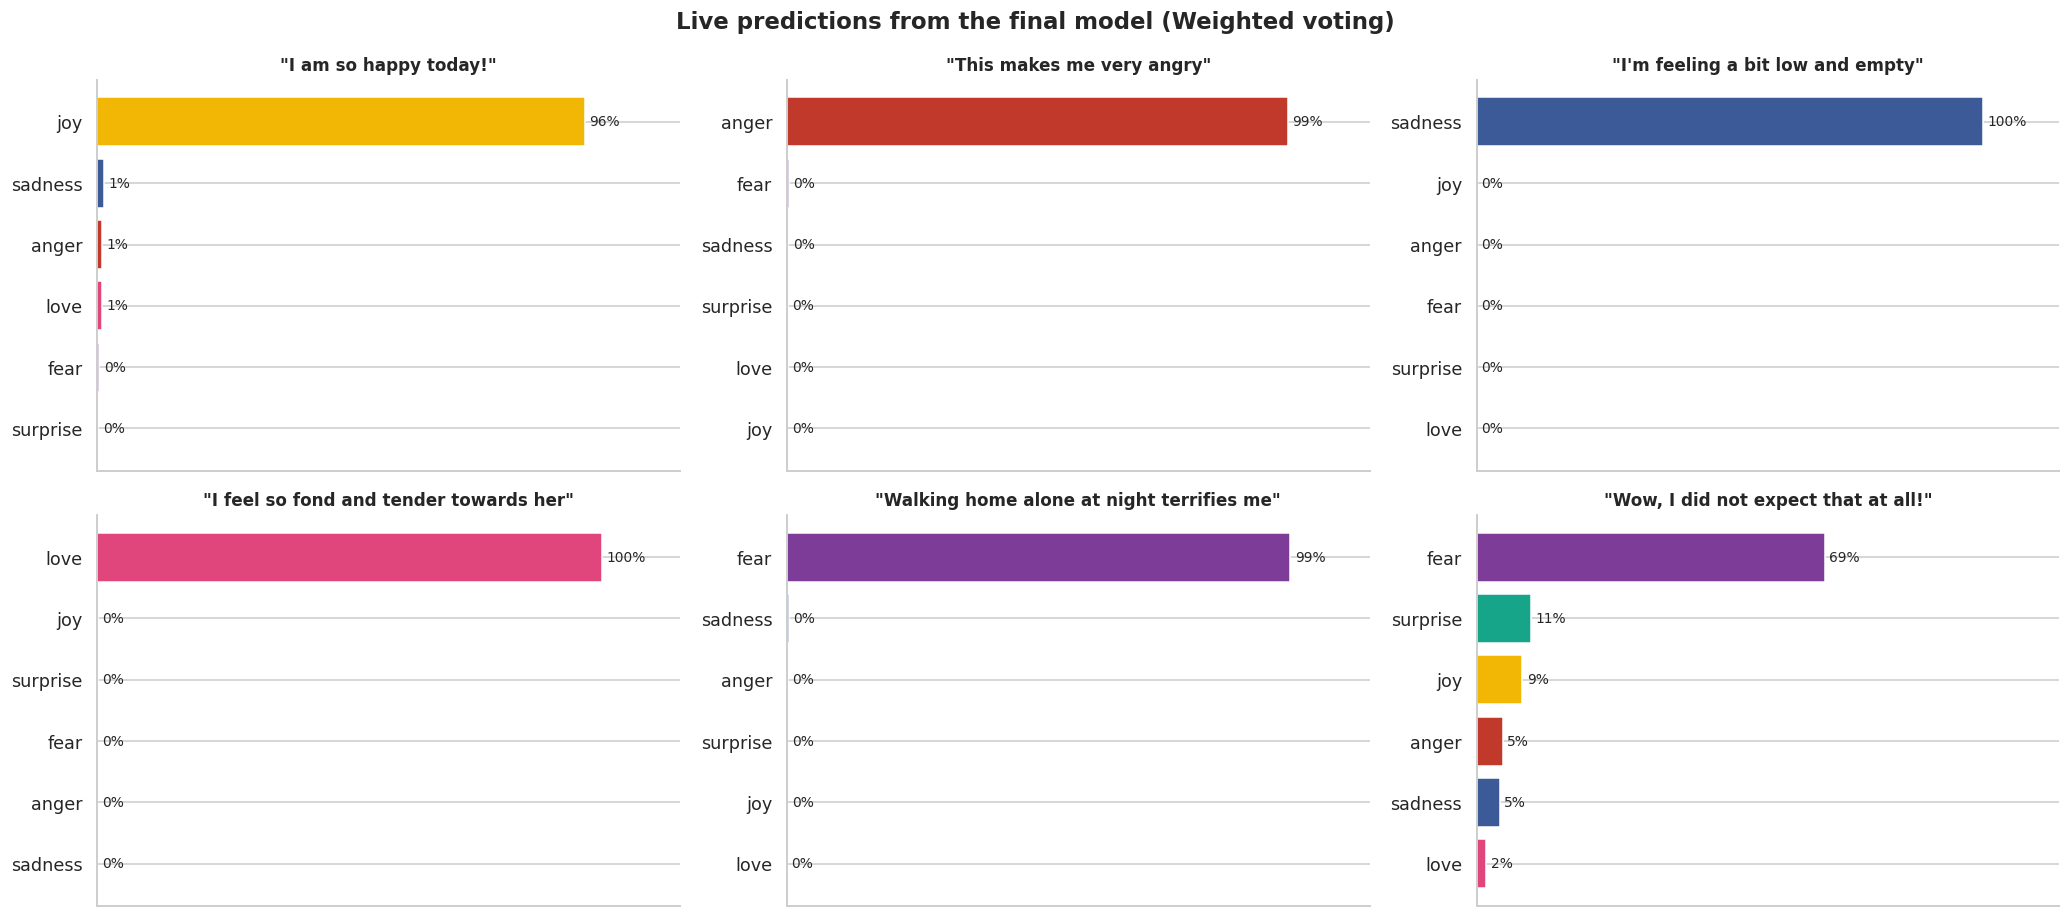

In [28]:
def predict_emotion(sentence):
    stemmed = stem_text(clean_text(sentence))
    seq = to_seq([stemmed])
    member_probs = [logreg.predict_proba(tfidf.transform([stemmed]))[0]] + \
                   [m.predict(seq, verbose=0)[0] for m in deep_models.values()] + \
                   [rb_probs(rb_loader([clean_text(sentence)]))[0]]
    if BEST == 'Stacking':
        return meta.predict_proba(np.hstack(member_probs)[None])[0]
    if BEST == 'Weighted voting':
        return np.tensordot(w, np.array(member_probs), axes=1)
    if BEST in probs:
        return member_probs[members.index(BEST)]
    return np.mean(member_probs, axis=0)


tries = ['I am so happy today!', 'This makes me very angry', "I'm feeling a bit low and empty",
         'I feel so fond and tender towards her', 'Walking home alone at night terrifies me',
         'Wow, I did not expect that at all!']
fig, axes = plt.subplots(2, 3, figsize=(19, 8.5))
for ax, s in zip(axes.flat, tries):
    p = predict_emotion(s)
    order = np.argsort(p)
    bars = ax.barh([EMOTIONS[i] for i in order], p[order], color=[COLORS[EMOTIONS[i]] for i in order])
    ax.bar_label(bars, labels=[f'{v:.0%}' for v in p[order]], padding=3, fontsize=9)
    ax.set_xlim(0, 1.15); ax.set_xticks([])
    ax.set_title(f'"{s}"', fontsize=11)
fig.suptitle(f'Live predictions from the final model ({BEST})', fontsize=15, fontweight='bold')
plt.tight_layout(); plt.show()

The last sentence shows a real limit. In the training tweets surprise is nearly always written with words
like *amazed, stunned, shocked* after "i feel". *"Wow, I did not expect that"* uses none of them, and in
the data the unexpected is more often frightening, so the model leans to **fear** and gives surprise only a
small share. Note that it says so with about 70% confidence, not 99%: a lower confidence like this is the
warning sign the calibration check above is about.

---
## 14. Final Summary

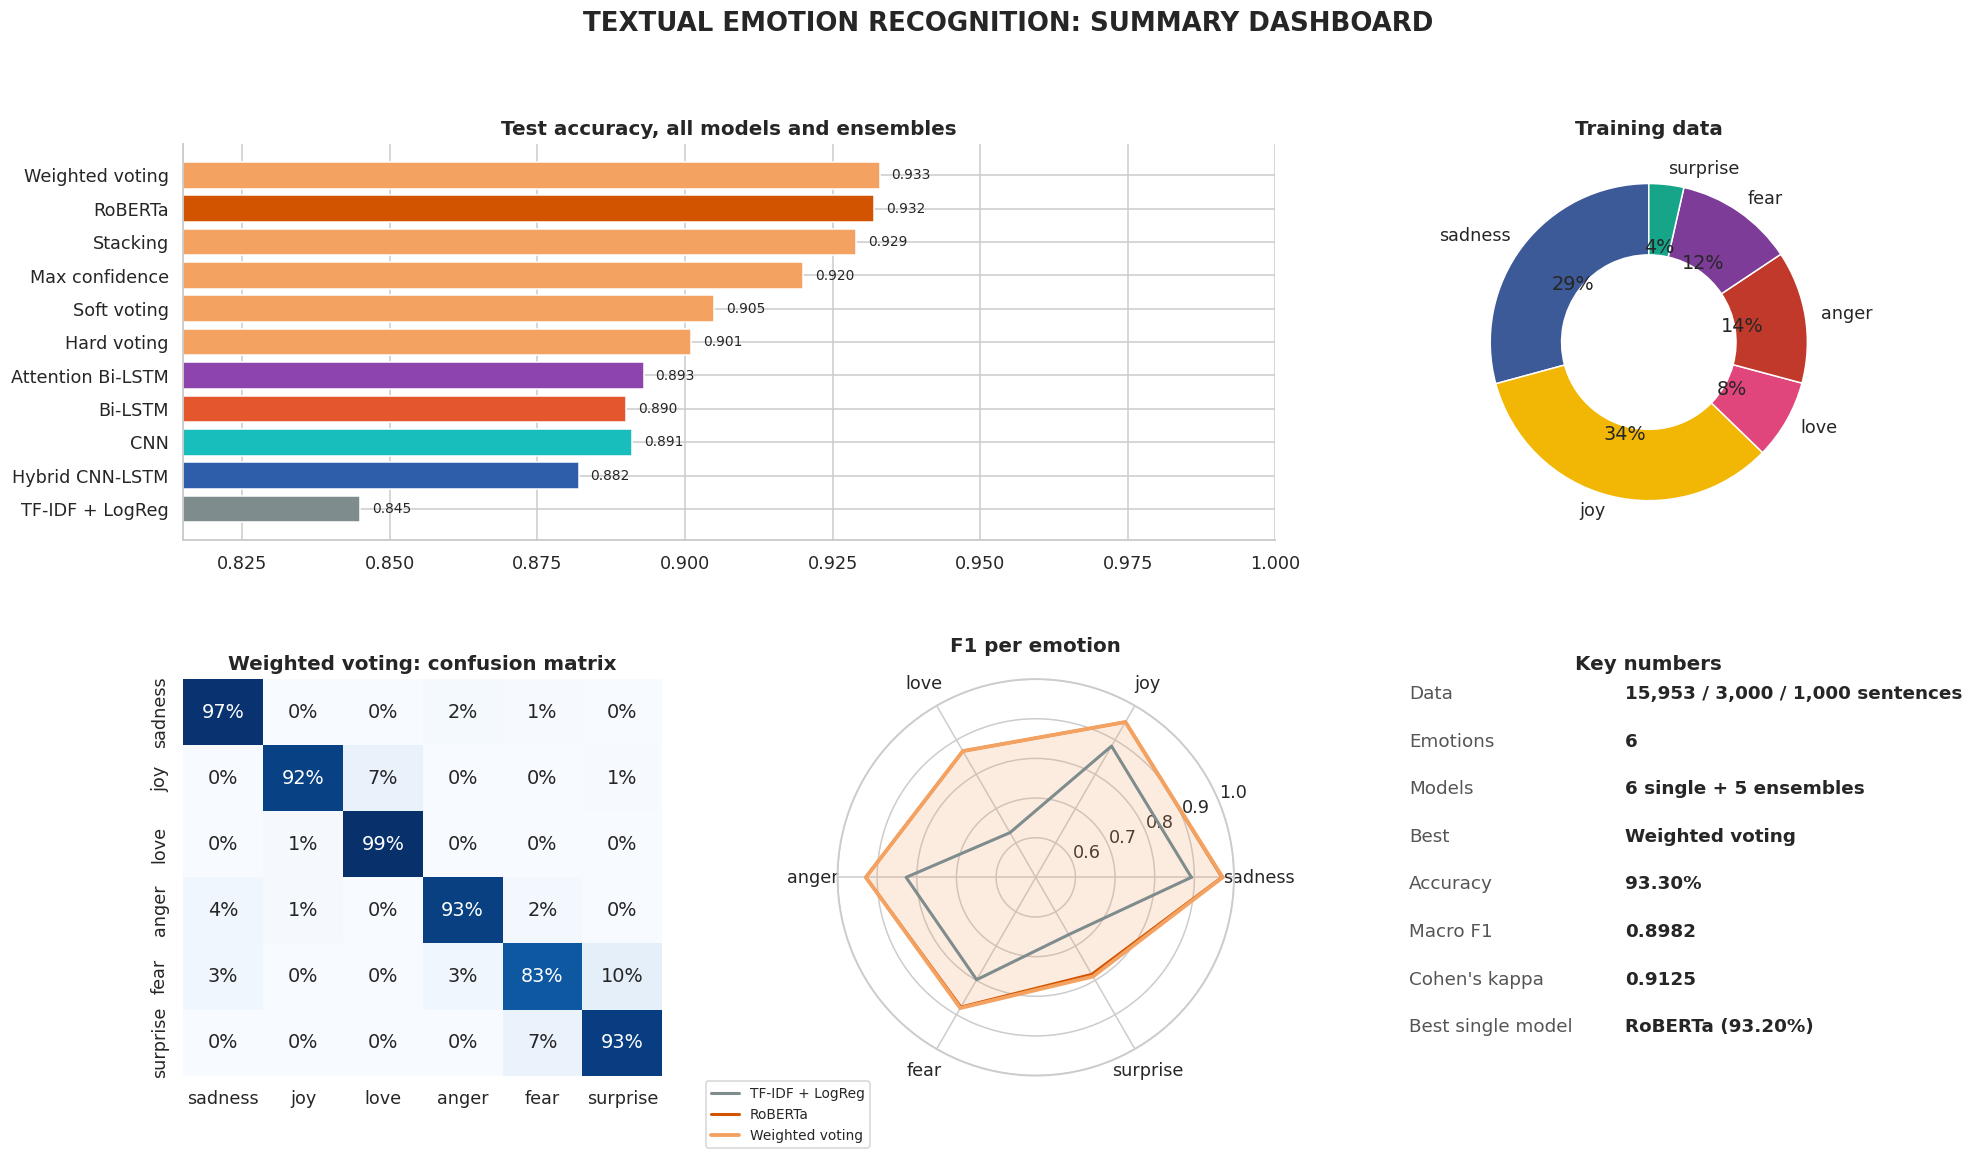

In [29]:
fig = plt.figure(figsize=(20, 11))
gs = fig.add_gridspec(2, 3, hspace=0.35, wspace=0.28)

ax = fig.add_subplot(gs[0, :2])
order = all_results.index[::-1]
ax.barh(order, all_results.loc[order, 'Accuracy'], color=[MODEL_COLORS.get(n, '#F4A261') for n in order])
for i, v in enumerate(all_results.loc[order, 'Accuracy']):
    ax.text(v + 0.002, i, f'{v:.3f}', va='center', fontsize=9)
ax.set_xlim(all_results['Accuracy'].min() - 0.03, 1.0)
ax.set_title('Test accuracy, all models and ensembles')

ax = fig.add_subplot(gs[0, 2])
ax.pie(counts.values, labels=counts.index, colors=[COLORS[e] for e in counts.index], autopct='%1.0f%%',
       wedgeprops={'width': 0.45, 'edgecolor': 'white'}, startangle=90)
ax.set_title('Training data')

ax = fig.add_subplot(gs[1, 0])
sns.heatmap(confusion_matrix(y_test, best_pred, normalize='true'), annot=True, fmt='.0%', cmap='Blues',
            cbar=False, xticklabels=EMOTIONS, yticklabels=EMOTIONS, ax=ax)
ax.set_title(f'{BEST}: confusion matrix')

ax = fig.add_subplot(gs[1, 1], projection='polar')
angles = np.linspace(0, 2 * np.pi, NUM_CLASSES, endpoint=False).tolist() + [0]
for name in ['TF-IDF + LogReg', results.index[0]]:
    vals = f1_table[name].tolist()
    ax.plot(angles, vals + vals[:1], lw=2, color=MODEL_COLORS[name], label=name)
best_f1 = f1_score(y_test, best_pred, average=None).tolist()
ax.plot(angles, best_f1 + best_f1[:1], lw=2.5, color='#F4A261', label=BEST)
ax.fill(angles, best_f1 + best_f1[:1], color='#F4A261', alpha=0.2)
ax.set_xticks(angles[:-1], EMOTIONS); ax.set_ylim(0.5, 1)
ax.set_title('F1 per emotion', pad=18); ax.legend(loc='lower left', bbox_to_anchor=(-0.35, -0.2), fontsize=9)

ax = fig.add_subplot(gs[1, 2]); ax.axis('off')
best_row = all_results.loc[BEST]
lines = [('Data', f'{len(train_data):,} / {len(val_data):,} / {len(test_data):,} sentences'),
         ('Emotions', '6'), ('Models', f'{len(probs)} single + {len(ensembles)} ensembles'),
         ('Best', BEST), ('Accuracy', f"{best_row['Accuracy']:.2%}"), ('Macro F1', f"{best_row['Macro F1']:.4f}"),
         ("Cohen's kappa", f"{best_row['Kappa']:.4f}"),
         ('Best single model', f"{results.index[0]} ({results['Accuracy'].iloc[0]:.2%})")]
for i, (k, v) in enumerate(lines):
    ax.text(0.0, 0.95 - i * 0.12, k, fontsize=12, color='#555555', transform=ax.transAxes)
    ax.text(0.45, 0.95 - i * 0.12, v, fontsize=12, fontweight='bold', transform=ax.transAxes)
ax.set_title('Key numbers')

fig.suptitle('TEXTUAL EMOTION RECOGNITION: SUMMARY DASHBOARD', fontsize=17, fontweight='bold', y=0.99)
plt.show()

### Conclusion

* A computer can recognise emotions in short sentences with **more than 93%** correct, from text alone.
* The steps are clear: a classic **TF-IDF + logistic regression** baseline gets about 85%; the deep models
  trained from scratch (LSTM, CNN, attention) reach about 89%; the pre-trained **RoBERTa** Transformer
  jumps to about 93%, because it already understands English before seeing a single emotion label.
* **Combining** models adds little on top of RoBERTa: the weighted vote, which learned on validation to
  trust RoBERTa most, beats it by one sentence in a thousand. The real gain of the ensembles was for the
  models trained from scratch, where they added about 1 point.
* **Softened class weights** and **macro F1** keep rare emotions like *surprise* and *love* from being
  ignored, without trading away overall accuracy.
* The test score is **clean**: duplicates and sentences shared with the test set were removed from
  training, and every ensemble weight was learned on validation data only.
* The models look at the **right words**, as attention and occlusion show, and their **confidence is
  meaningful**: answering only when confident gives very high accuracy.

**Limits**

| Limit | Why it matters |
|---|---|
| One emotion per sentence | Real text often mixes feelings, like joy and surprise together |
| Labels come from hashtags | Some labels are debatable, which caps the best possible score |
| Short English tweets | Long texts, other languages and sarcasm are not covered |

---
*CVIS Hands-on Training Project, BRAC University. Faiaz Abrar Zaman Pronoy (22301061).*